<a href="https://colab.research.google.com/github/syifaymd/Tugas-Kelompok-7/blob/main/SARIMA_SARIMAX_Sulawesi_LAG_BOXCOX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Perbandingan SARIMA–SARIMAX: Produksi Padi di Sulawesi

Analisis **6 provinsi Sulawesi dan agregat pulau** secara terpisah, dengan periode uji 12 bulan dan peramalan 12 bulan. **Y = produksi padi; X = luas panen; Curah_Hujan_mm = curah hujan.**

**Urutan analisis:** validasi data → EDA → pemeriksaan kestabilan ragam (profil Box–Cox dan transformasi bila diperlukan) → pemeriksaan lag **X dan curah hujan** → uji kestasioneran rataan (ADF, KPSS, differencing) → identifikasi ACF/PACF → grid AIC SARIMA/SARIMAX → evaluasi holdout → diagnostik residual → peramalan.

- Semua estimasi λ, pemilihan lag, d/D, dan orde model menggunakan **data latih saja**; 12 bulan terakhir disimpan sebagai data uji.
- **Kedua variabel eksogen** dipilih lag-nya **0–6 bulan** per provinsi melalui korelasi deret terdiferensi. Lag terbaik bersifat eksploratif, bukan bukti kausal atau otomatis model terbaik.
- Box–Cox: bila interval kepercayaan 95% bagi λ **mencakup 1**, pertahankan Y pada skala asli; bila **tidak mencakup 1**, lakukan transformasi Box–Cox dengan λ hasil estimasi. Jika λ ≈ 0, ini mendekati transformasi log. Nilai nol ditangani melalui penambahan konstanta 1 yang ditetapkan di awal (tanpa melihat data uji).
- SARIMAX **skenario** menggunakan eksogen yang dibentuk tanpa melihat masa depan; SARIMAX **kondisional** menggunakan eksogen aktual pada data uji dan **tidak boleh** disamakan dengan ramalan operasional.
- Ramalan setelah invers Box–Cox adalah **median kondisional (tanpa koreksi bias)**. Interval 95% bersifat kondisional pada skenario eksogen dan parameter model; ketidakpastian prakiraan X/hujan tidak tercakup.
- Agregat hujan Sulawesi adalah rerata provinsi sederhana, bukan rata-rata tertimbang luas.

**Persyaratan data Excel:** `Provinsi`, `Tahun`, `Bulan`, `Y`, `X`, `Curah_Hujan_mm`.


## 0. Pengaturan

In [1]:
import warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

# ---- PARAMETER (ubah sesuai kebutuhan) ----
PULAU_PILIH = "Sulawesi"   # pilihan: Sumatera, Jawa, Bali-Nusa Tenggara, Kalimantan, Sulawesi, Maluku, Papua
PETA_PULAU = {
    "Sumatera": ["ACEH", "SUMATERA UTARA", "SUMATERA BARAT", "RIAU", "JAMBI", "SUMATERA SELATAN", "BENGKULU", "LAMPUNG",
                 "KEPULAUAN BANGKA BELITUNG", "KEPULAUAN RIAU"],
    "Jawa": ["DKI JAKARTA", "JAWA BARAT", "JAWA TENGAH", "DI YOGYAKARTA", "JAWA TIMUR", "BANTEN"],
    "Bali-Nusa Tenggara": ["BALI", "NUSA TENGGARA BARAT", "NUSA TENGGARA TIMUR"],
    "Kalimantan": ["KALIMANTAN BARAT", "KALIMANTAN TENGAH", "KALIMANTAN SELATAN", "KALIMANTAN TIMUR", "KALIMANTAN UTARA"],
    "Sulawesi": ["SULAWESI UTARA", "GORONTALO", "SULAWESI TENGAH", "SULAWESI BARAT", "SULAWESI SELATAN", "SULAWESI TENGGARA"],
    "Maluku": ["MALUKU", "MALUKU UTARA"],
    "Papua": ["PAPUA BARAT", "PAPUA BARAT DAYA", "PAPUA", "PAPUA SELATAN", "PAPUA TENGAH", "PAPUA PENGUNUNGAN"],
}
PULAU = PETA_PULAU[PULAU_PILIH]
TOTAL = f"TOTAL {PULAU_PILIH.upper()}"
TARGET = "Y"                           # variabel yang diramal
EXOG = ["X", "Curah_Hujan_mm"]         # variabel eksogen (isi [] untuk SARIMA biasa)
S = 12                                 # periode musiman (bulanan)
H = 12                                 # horizon peramalan (bulan)
TEST = 12                              # panjang data uji (holdout)
BOXCOX_ALPHA = 0.05                     # interval kepercayaan lambda Box-Cox 95%
BOXCOX_SHIFT_ZERO = 1.0                 # gunakan Y+1 secara konsisten (juga aman jika nol baru muncul di uji)
# Y ditransformasi secara otomatis berdasarkan keputusan CI lambda; eksogen tetap log1p.
from IPython.display import display
import math
# Pengaturan lag (lag k berarti variabel eksogen dari t-k untuk memodelkan Y[t])
MAX_LAG = 6                               # kandidat lag luas panen dan curah hujan 0..6
AUTO_LAG = True                           # pilih kedua lag memakai data latih
LAG_MANUAL = {"X": 0, "Curah_Hujan_mm": 0} # jika AUTO_LAG=False
MIN_ABS_CCF = 0.25                       # hanya tanda korelasi lemah; tidak memaksa lag 0
START_LAG = MAX_LAG                     # sama untuk SARIMA/SARIMAX dan seluruh calon lag
MAX_ITER_GRID = 120


## 1. Data

In [2]:
from google.colab import files
up = files.upload()                    # pilih Data_Padi.xlsx
fname = list(up.keys())[0]
raw = pd.read_excel(fname)
raw.head()

Saving Data_1_Updated.xlsx to Data_1_Updated.xlsx


,Provinsi,Tahun,Bulan,Y,X,Curah_Hujan_mm
0,ACEH,2018,Januari,76118.47,14541.53,271.773066
1,ACEH,2018,Februari,142876.76,27075.77,107.421202
2,ACEH,2018,Maret,375841.91,66403.96,173.163008
3,ACEH,2018,April,336742.80,58507.03,235.422620
4,ACEH,2018,Mei,96372.36,16867.65,241.453734


In [3]:
bulan = {"januari":1,"februari":2,"maret":3,"april":4,"mei":5,"juni":6,"juli":7,
         "agustus":8,"september":9,"oktober":10,"nopember":11,"november":11,"desember":12}
kolom = ["Provinsi","Tahun","Bulan",TARGET]+EXOG
assert set(kolom).issubset(raw.columns), f"Kolom belum lengkap: {set(kolom)-set(raw.columns)}"
df = raw[kolom].copy()
df["Provinsi"] = df["Provinsi"].astype(str).str.strip().str.upper()
df["bln"] = df["Bulan"].astype(str).str.strip().str.lower().map(bulan)
assert df["bln"].notna().all(), "Nama bulan ada yang tidak dikenal"
df["Tahun"] = pd.to_numeric(df["Tahun"], errors="raise").astype(int)
df["Tanggal"] = pd.to_datetime(dict(year=df["Tahun"],month=df["bln"].astype(int),day=1))
for c in [TARGET]+EXOG: df[c] = pd.to_numeric(df[c], errors="coerce")
assert set(PULAU).issubset(df["Provinsi"]), f"Provinsi tidak ada: {set(PULAU)-set(df['Provinsi'])}"
pl = df[df["Provinsi"].isin(PULAU)].copy()
assert not pl.duplicated(["Provinsi","Tanggal"]).any(), "Ada duplikasi provinsi/bulan: jangan dijumlahkan diam-diam"
assert not pl[[TARGET]+EXOG].isna().any().any(), "Ada Y/X/hujan hilang atau bukan numerik"
assert (pl[[TARGET]+EXOG]>=0).all().all(), "Box-Cox dan log1p eksogen memerlukan Y/X/hujan >= 0"
idx = pd.date_range(pl["Tanggal"].min(),pl["Tanggal"].max(),freq="MS")
seri = {}
for p in PULAU:
    v = pl[pl["Provinsi"]==p].set_index("Tanggal").sort_index().reindex(idx)
    assert not v[[TARGET]+EXOG].isna().any().any(), f"Bulan tidak lengkap: {p}"
    seri[p] = v[[TARGET]+EXOG].astype(float)
seri[TOTAL] = pd.DataFrame(index=idx)
for c in [TARGET,"X"]: seri[TOTAL][c] = sum(seri[p][c] for p in PULAU)
seri[TOTAL]["Curah_Hujan_mm"] = pd.concat([seri[p]["Curah_Hujan_mm"] for p in PULAU],axis=1).mean(axis=1)
MODEL_PROV = PULAU+[TOTAL]  # jangan membuang provinsi saat ada nilai 0
assert len(idx)>TEST+START_LAG+4*S, "Data bulanan terlalu pendek"
data = {c:pd.DataFrame({p:seri[p][c] for p in MODEL_PROV},index=idx) for c in [TARGET]+EXOG}
print("Pulau:",PULAU_PILIH,"| 6 provinsi + agregat")
print("Periode:",idx.min().date(),"s.d.",idx.max().date(),"|",len(idx),"bulan")
print("Latih s.d.",idx[-TEST-1].date(),"| uji",idx[-TEST].date(),"s.d.",idx[-1].date())
print("Total missing setelah validasi:",sum(v.isna().sum().sum() for v in data.values()))
display(data[TARGET].describe().T.round(1))

Pulau: Sulawesi | 6 provinsi + agregat
Periode: 2018-01-01 s.d. 2026-08-01 | 104 bulan
Latih s.d. 2025-08-01 | uji 2025-09-01 s.d. 2026-08-01
Total missing setelah validasi: 0


,count,mean,std,min,25%,50%,75%,max
SULAWESI UTARA,104.0,22035.6,5806.9,11720.6,18108.5,21593.1,25201.1,41605.1
GORONTALO,104.0,21032.5,12097.8,2264.0,12969.1,18583.2,26251.4,63337.5
SULAWESI TENGAH,104.0,69444.8,31358.5,17116.6,45060.2,68663.2,91472.2,155731.4
SULAWESI BARAT,104.0,27793.6,16308.0,3554.1,17087.3,24592.6,36779.3,98641.0
SULAWESI SELATAN,104.0,431343.3,302973.5,23784.3,157000.7,380873.1,671783.6,1163518.0
SULAWESI TENGGARA,104.0,45303.3,23495.2,4565.5,29174.2,40757.1,57303.3,119215.3
TOTAL SULAWESI,104.0,616953.1,333266.0,131995.8,309994.8,577064.2,879394.0,1427438.8


## 2. EDA

### 2.1 Ringkasan dan kualitas data

In [4]:
ringkas = pd.DataFrame({
    "rata-rata": data[TARGET].mean(),
    "median": data[TARGET].median(),
    "std": data[TARGET].std(),
    "min": data[TARGET].min(),
    "maks": data[TARGET].max(),
    "CV (%)": data[TARGET].std() / data[TARGET].mean() * 100,
    "jumlah nol": (data[TARGET] == 0).sum(),
}).round(1)
ringkas

,rata-rata,median,std,min,maks,CV (%),jumlah nol
SULAWESI UTARA,22035.6,21593.1,5806.9,11720.6,41605.1,26.4,0
GORONTALO,21032.5,18583.2,12097.8,2264.0,63337.5,57.5,0
SULAWESI TENGAH,69444.8,68663.2,31358.5,17116.6,155731.4,45.2,0
SULAWESI BARAT,27793.6,24592.6,16308.0,3554.1,98641.0,58.7,0
SULAWESI SELATAN,431343.3,380873.1,302973.5,23784.3,1163518.0,70.2,0
SULAWESI TENGGARA,45303.3,40757.1,23495.2,4565.5,119215.3,51.9,0
TOTAL SULAWESI,616953.1,577064.2,333266.0,131995.8,1427438.8,54.0,0


### 2.2 Plot deret waktu

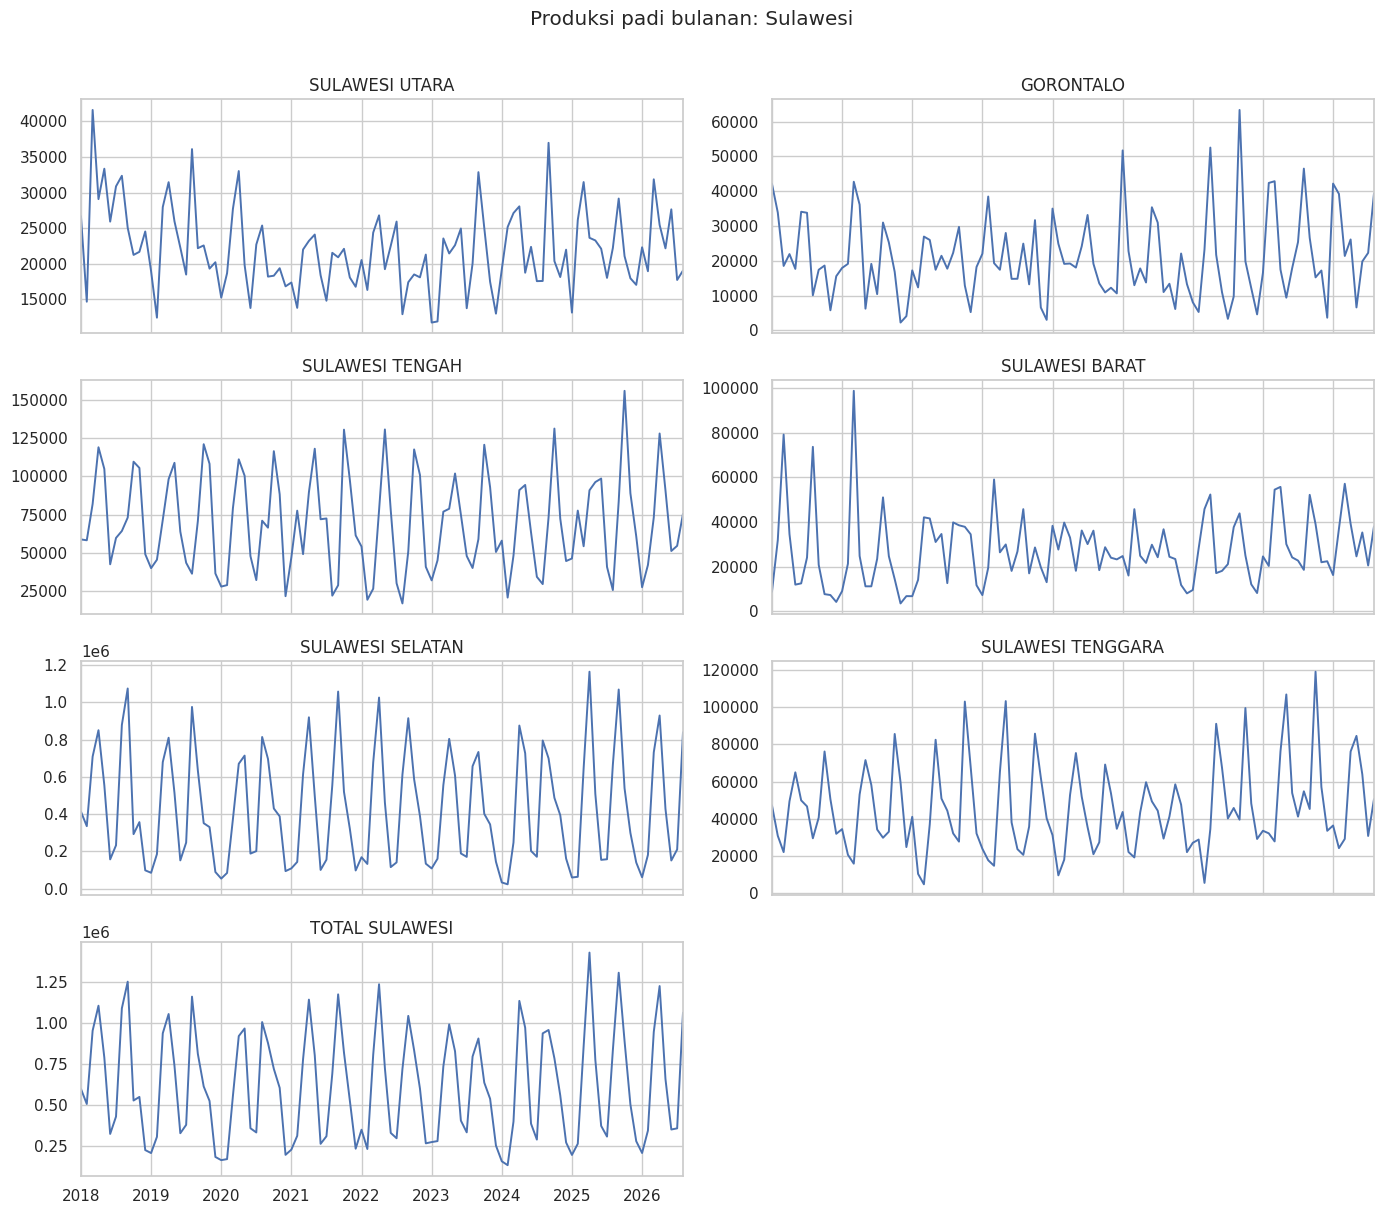

In [5]:
import math
fig, axes = plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12),sharex=True)
for ax,p in zip(axes.ravel(),MODEL_PROV):
    data[TARGET][p].plot(ax=ax,lw=1.4); ax.set_title(p); ax.set_xlabel("")
for ax in axes.ravel()[len(MODEL_PROV):]:ax.axis("off")
fig.suptitle(f"Produksi padi bulanan: {PULAU_PILIH}",y=1.01)
plt.tight_layout();plt.show()

### 2.3 Pola musiman

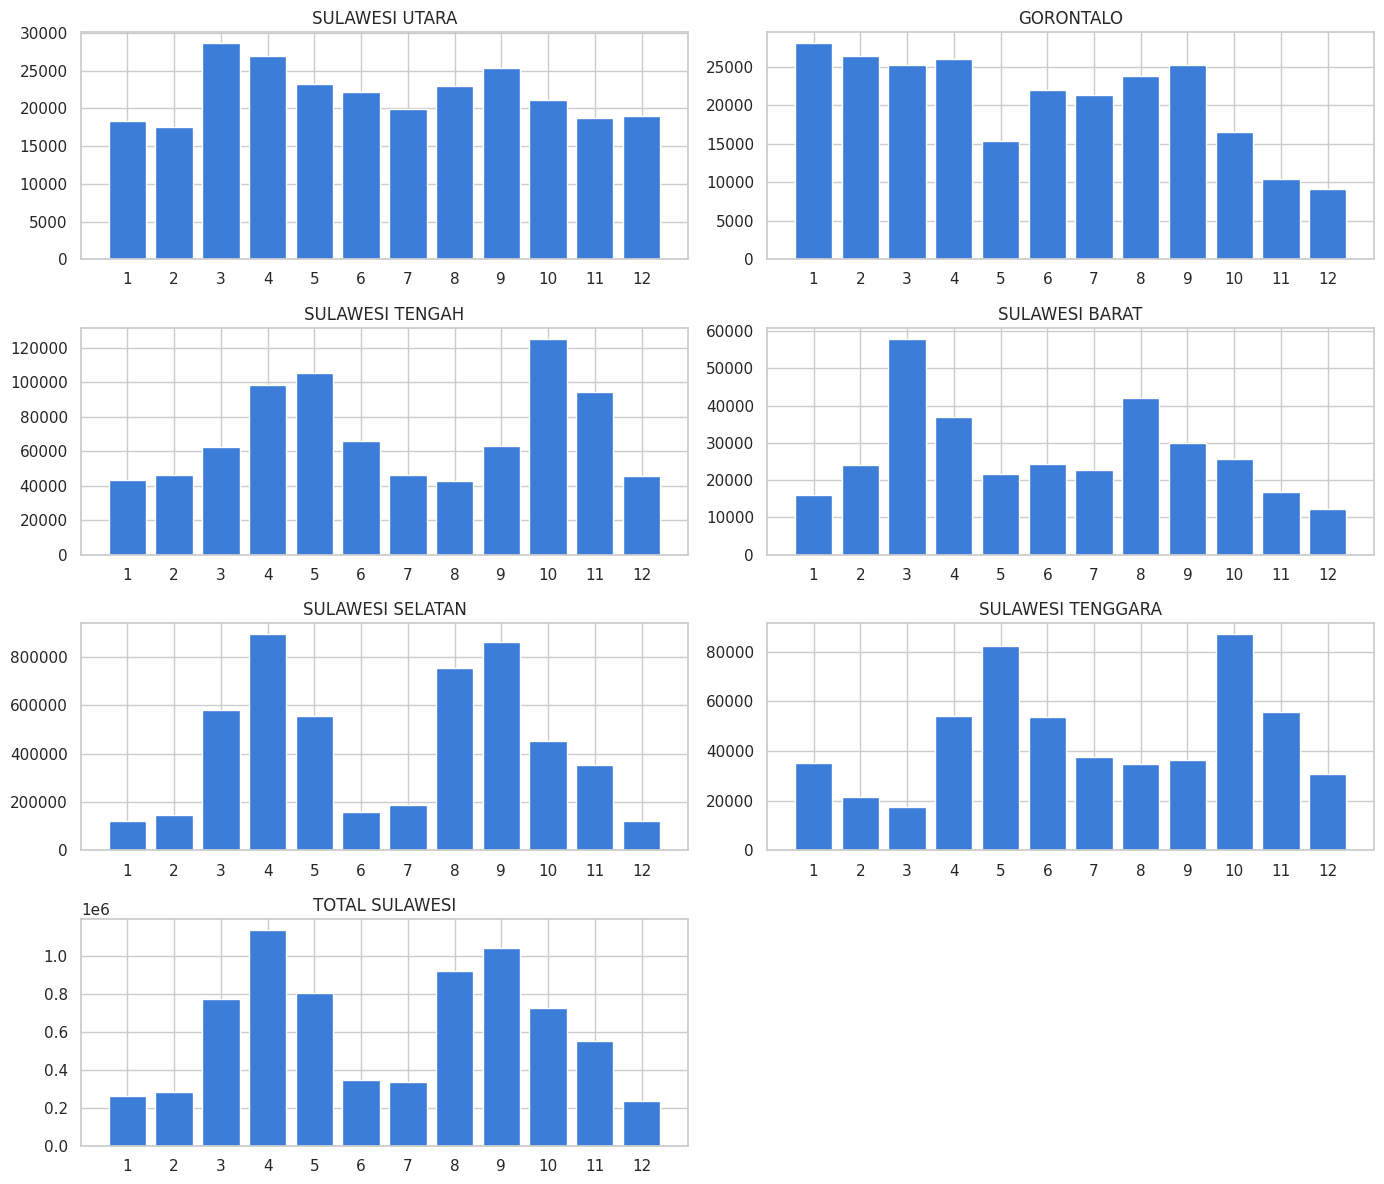

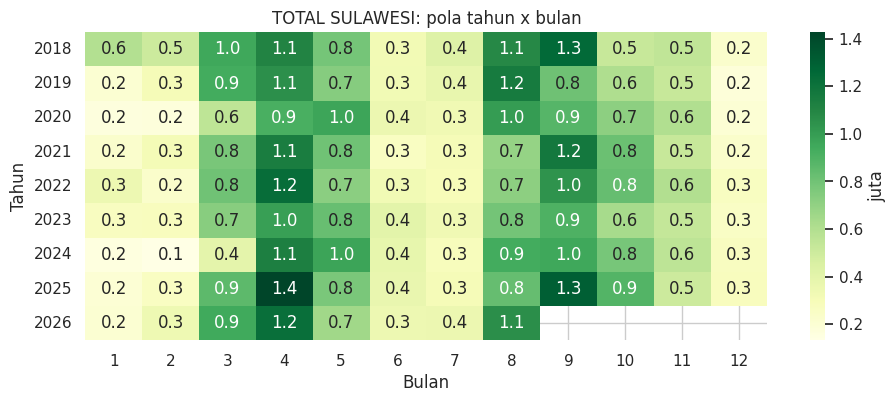

In [6]:
fig, axes = plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    s = data[TARGET][p]
    tab = s.groupby(s.index.month).mean()
    ax.bar(tab.index,tab.values,color="#3b7dd8");ax.set_title(p);ax.set_xticks(range(1,13))
for ax in axes.ravel()[len(MODEL_PROV):]:ax.axis("off")
plt.tight_layout();plt.show()
t=data[TARGET][TOTAL]
hm=t.to_frame("v").assign(Tahun=t.index.year,Bulan=t.index.month).pivot(index="Tahun",columns="Bulan",values="v")
plt.figure(figsize=(11,4));sns.heatmap(hm/1e6,cmap="YlGn",annot=True,fmt=".1f",cbar_kws={"label":"juta"})
plt.title(f"{TOTAL}: pola tahun x bulan");plt.show()

### 2.4 Pemeriksaan kestabilan ragam (profil likelihood Box–Cox)

Box–Cox dipakai sebagai **diagnostik dan upaya stabilisasi ragam Y** sebelum uji stasioneritas dalam rataan. Perhitungan menggunakan **Y data latih saja** (setelah 6 bulan pertama dikeluarkan agar sesuai dengan awal model). Karena produksi padi bernilai nonnegatif, gunakan **`shift = 1` secara konsisten** pada semua seri yang perlu ditransformasi. Ini juga mencegah kegagalan saat nilai nol baru muncul pada data uji.

\[
BC(y;\lambda)=\begin{cases}
\dfrac{(y+c)^\lambda-1}{\lambda}, &\lambda\ne 0 \\
\ln(y+c), &\lambda=0.
\end{cases}
\]

Periksa kurva profil log-likelihood Box–Cox, \(\hat\lambda\), dan CI 95%. **Jika 1 termasuk CI 95% λ, pertahankan Y asli; jika 1 tidak termasuk CI, gunakan transformasi Box–Cox dengan λ estimasi.** Ini aturan kerja berbasis CI λ dalam asumsi model Box–Cox, **bukan uji formal stasioneritas ragam** atau jaminan varian residual konstan. Pengujian heteroskedastisitas residual merupakan pemeriksaan tambahan setelah model. Semua keputusan diterapkan per provinsi, termasuk agregat Sulawesi.

,Lambda_hat,CI_bawah,CI_atas,Shift,Lambda_dipakai,Transformasi,Keputusan
Provinsi,,,,,,,
SULAWESI UTARA,0.1774,-0.5231,0.8788,1.0,0.1774,Box-Cox,CI tidak memuat 1: transformasi
GORONTALO,0.3438,0.0802,0.6169,1.0,0.3438,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI TENGAH,0.4880,0.0622,0.9306,1.0,0.4880,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI BARAT,0.2981,0.0227,0.5766,1.0,0.2981,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI SELATAN,0.3102,0.0598,0.5764,1.0,0.3102,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI TENGGARA,0.4316,0.1556,0.7297,1.0,0.4316,Box-Cox,CI tidak memuat 1: transformasi
TOTAL SULAWESI,0.3095,-0.0823,0.7104,1.0,0.3095,Box-Cox,CI tidak memuat 1: transformasi


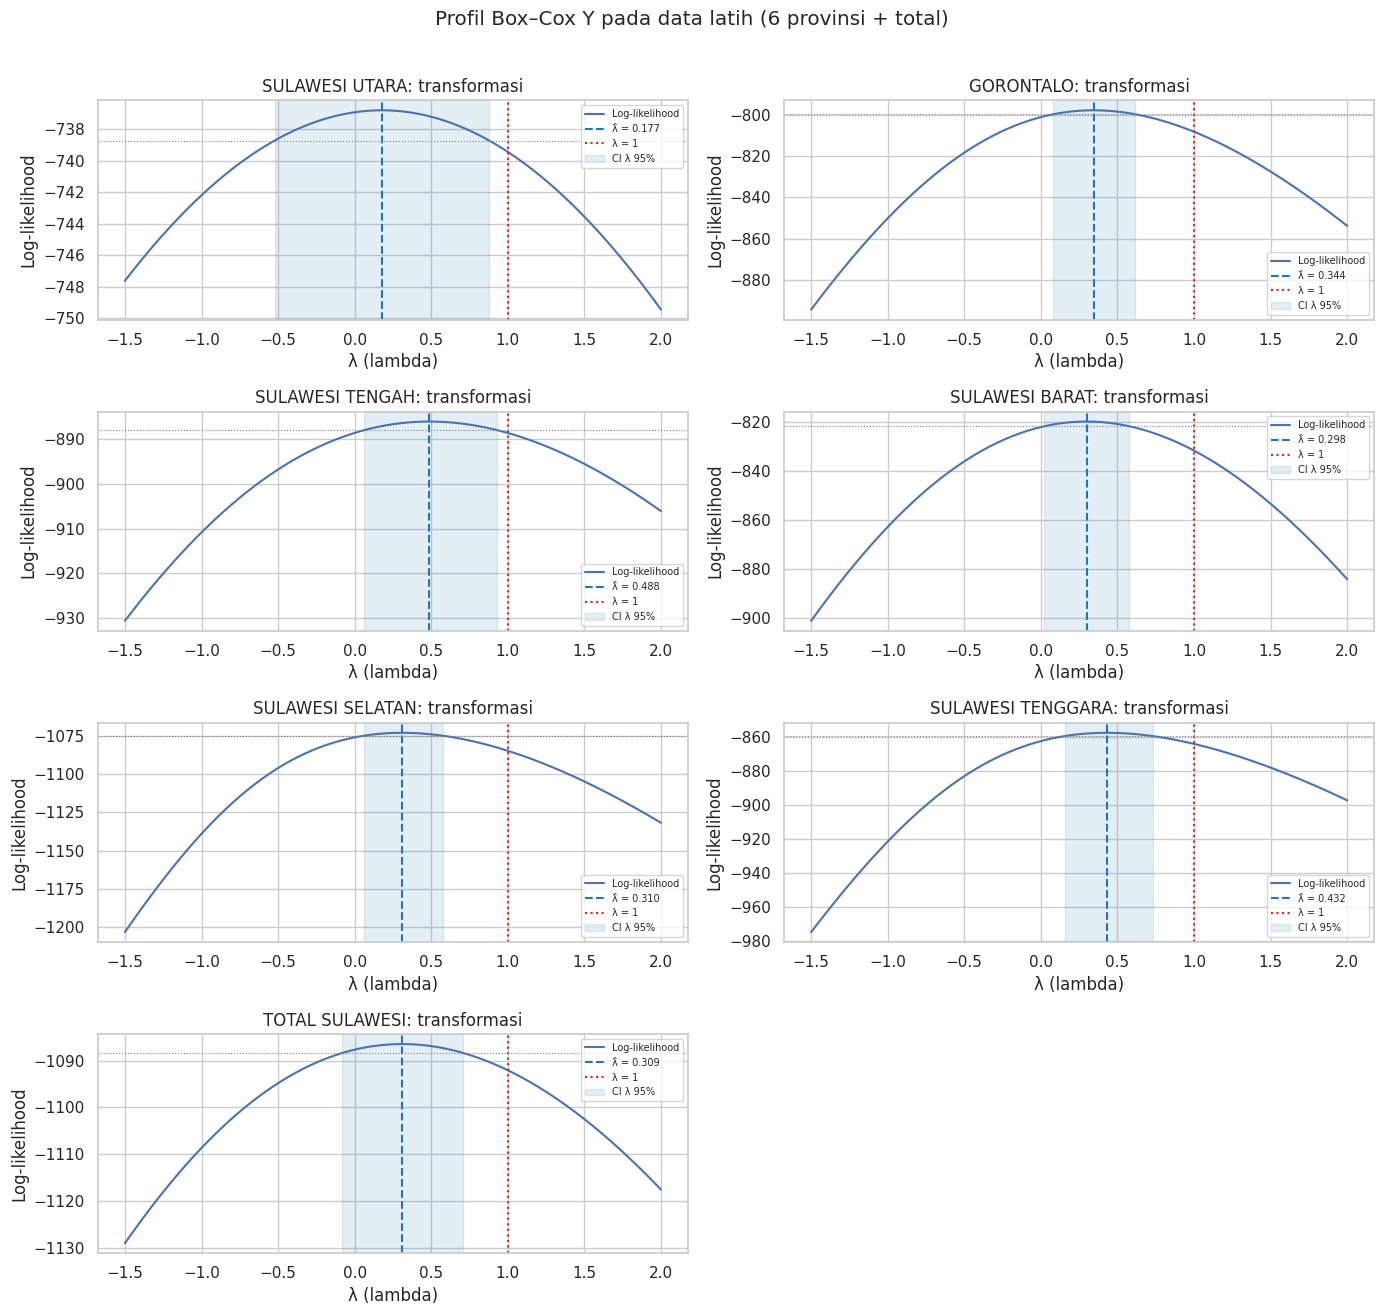

In [7]:
from scipy.stats import boxcox as stats_boxcox, boxcox_llf, chi2
from scipy.special import boxcox as special_boxcox, inv_boxcox

boxcox_status={}; boxcox_rows=[]
for p in MODEL_PROV:
    train=data[TARGET][p].iloc[START_LAG:-TEST].astype(float)
    assert len(train)>=36 and train.nunique()>=3, f"Data Y tidak memadai untuk Box-Cox: {p}"
    shift=float(BOXCOX_SHIFT_ZERO)  # tambah 1 pada semua seri, termasuk jika data latih tidak mengandung nol
    arr=train.to_numpy()+shift
    assert np.all(arr>0)
    _,lam_hat,ci=stats_boxcox(arr,alpha=BOXCOX_ALPHA)
    lo,hi=map(float,ci)
    perform=(not(lo<=1.0<=hi))
    boxcox_status[p]={"Lambda_hat":float(lam_hat), "CI_bawah":lo,"CI_atas":hi,
                      "Shift":shift,"Lambda_dipakai":float(lam_hat) if perform else 1.0,
                      "Transformasi":"Box-Cox" if perform else "Tidak (Y asli)"}
    boxcox_rows.append({"Provinsi":p,**boxcox_status[p],
                        "Keputusan":"CI tidak memuat 1: transformasi" if perform else "CI memuat 1: tanpa transformasi"})
tabel_boxcox=pd.DataFrame(boxcox_rows).set_index("Provinsi")
display(tabel_boxcox.round(4))

def transform_y(s,p):
    """Gunakan Box-Cox Y hanya bila CI 95% lambda dari data LATIH tak memuat 1."""
    s=s.astype(float).copy()
    cfg=boxcox_status[p]
    if cfg["Transformasi"]=="Box-Cox":
        shifted=s+cfg["Shift"]
        if not (shifted>0).all():
            raise ValueError(f"Nilai Y di luar domain Box-Cox {p}; periksa shift dan data uji")
        return pd.Series(special_boxcox(shifted.to_numpy(),cfg["Lambda_dipakai"]),index=s.index,name=s.name)
    return s

# Profil log-likelihood tiap provinsi: garis biru = lambda-hat,
# merah = lambda 1 (tanpa transformasi), arsiran = CI 95%.
fig,axes=plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,13))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    cfg=boxcox_status[p]
    arr=data[TARGET][p].iloc[START_LAG:-TEST].to_numpy()+cfg["Shift"]
    lm=cfg["Lambda_hat"];lo=cfg["CI_bawah"];hi=cfg["CI_atas"]
    a=min(-1.5,lm-1.0,lo-.25,1-.5);b=max(2.0,lm+1.0,hi+.25,1+.5)
    candidates=np.linspace(a,b,300)
    ll=np.array([boxcox_llf(lam,arr) for lam in candidates])
    llpeak=boxcox_llf(lm,arr)
    threshold=llpeak-0.5*chi2.ppf(1-BOXCOX_ALPHA,df=1)
    ax.plot(candidates,ll,label="Log-likelihood")
    ax.axvline(lm,color="tab:blue",ls="--",label=f"λ̂ = {lm:.3f}")
    ax.axvline(1,color="tab:red",ls=":",label="λ = 1")
    ax.axhline(threshold,color="grey",ls=":",lw=.8)
    ax.axvspan(lo,hi,color="tab:blue",alpha=.12,label="CI λ 95%")
    ax.set_title(f"{p}: {'transformasi' if cfg['Transformasi']=='Box-Cox' else 'tanpa transformasi'}")
    ax.set_xlabel("λ (lambda)");ax.set_ylabel("Log-likelihood")
    ax.legend(fontsize=7,loc="best")
for ax in axes.ravel()[len(MODEL_PROV):]:ax.axis("off")
plt.suptitle("Profil Box–Cox Y pada data latih (6 provinsi + total)",y=1.01)
plt.tight_layout();plt.show()

**Pemeriksaan visual sebelum/sesudah transformasi:** plot di bawah memperlihatkan deret Y asli dan hasil Box–Cox pada **data latih** untuk semua provinsi. Jika CI mencakup 1, panel hasil tetap dalam skala asli. Skala sumbu kanan dan kiri **tidak sama**, sehingga bandingkan pola variasi, bukan amplitudo absolut antarskala.

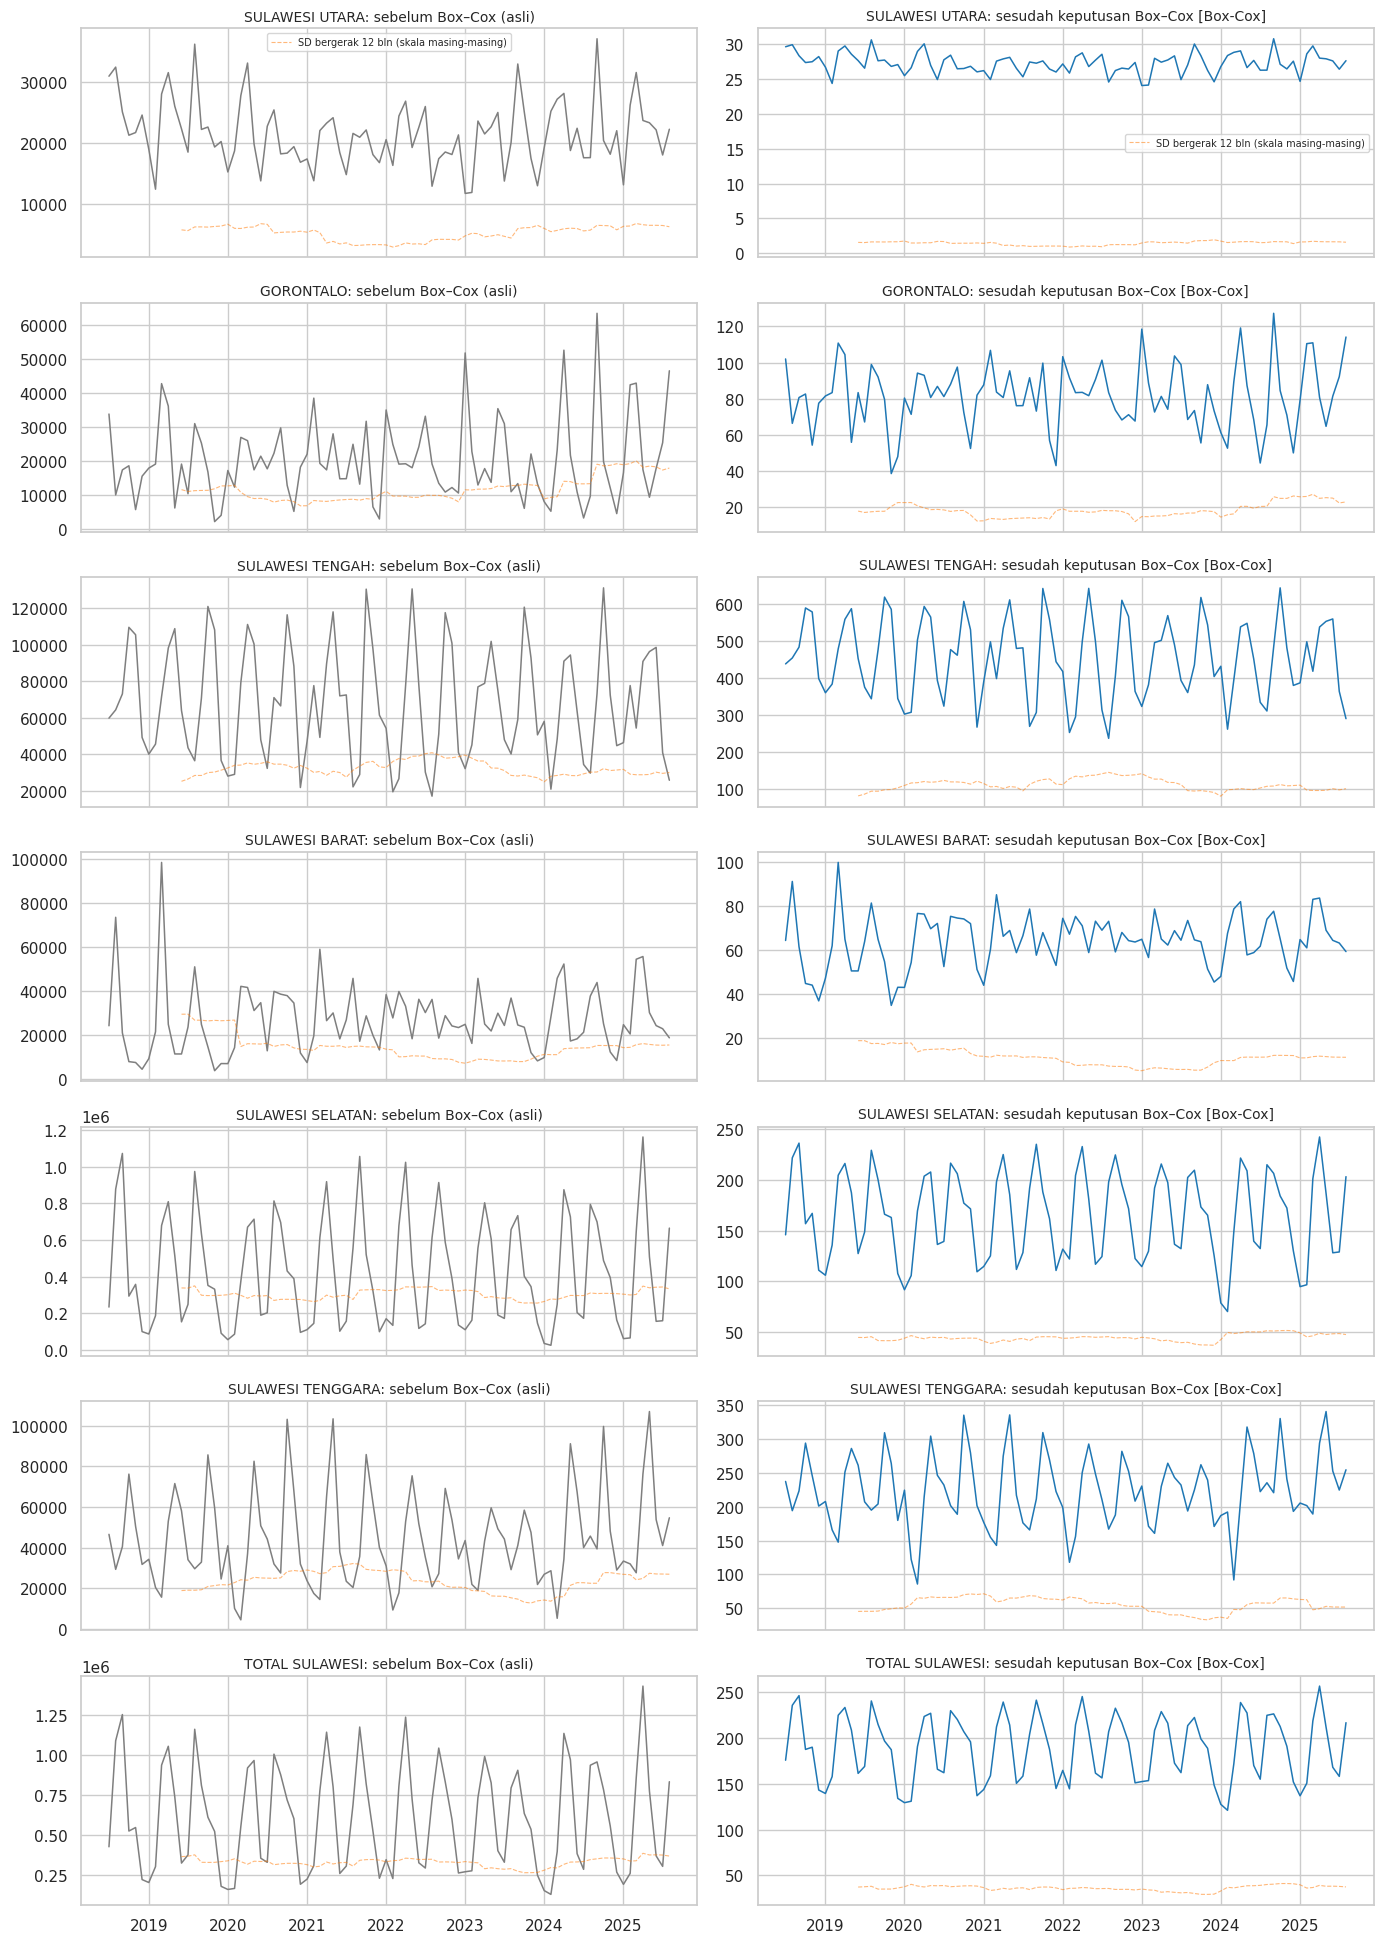

In [8]:
fig,axes=plt.subplots(len(MODEL_PROV),2,figsize=(14,2.8*len(MODEL_PROV)),sharex=True)
for i,p in enumerate(MODEL_PROV):
    z=data[TARGET][p].iloc[START_LAG:-TEST]
    zt=transform_y(z,p)
    axes[i,0].plot(z.index,z,color="tab:gray",lw=1.1)
    axes[i,0].set_title(f"{p}: sebelum Box–Cox (asli)",fontsize=10)
    axes[i,1].plot(zt.index,zt,color="tab:blue",lw=1.1)
    axes[i,1].set_title(f"{p}: sesudah keputusan Box–Cox [{boxcox_status[p]['Transformasi']}]",fontsize=10)
    for j,v in [(0,z),(1,zt)]:
        r=v.rolling(12,min_periods=12).std()
        axes[i,j].plot(r.index,r,color="tab:orange",alpha=.55,lw=.8,ls="--",
                       label="SD bergerak 12 bln (skala masing-masing)")
        if i==0:axes[i,j].legend(fontsize=7)
plt.tight_layout();plt.show()

### 2.5 Dekomposisi STL dan kekuatan musiman/tren (Y setelah keputusan Box–Cox)

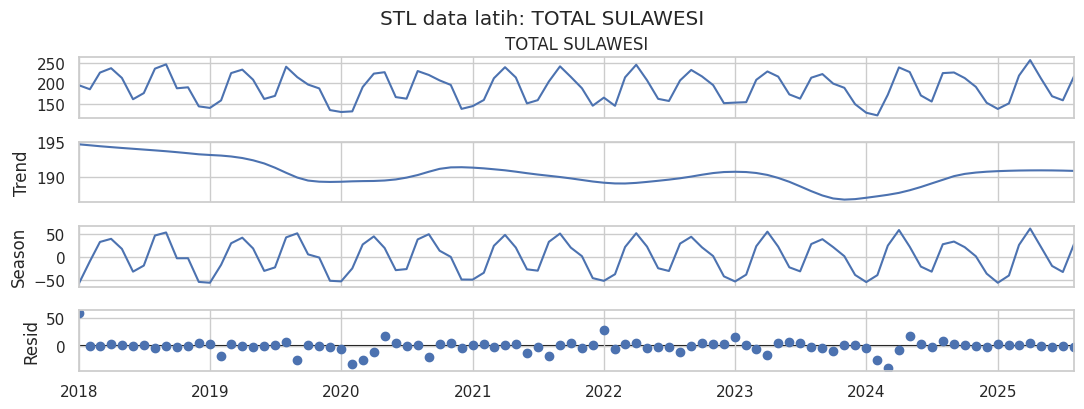

,Kekuatan tren,Kekuatan musiman
Provinsi,,
SULAWESI UTARA,0.356,0.625
GORONTALO,0.086,0.400
SULAWESI TENGAH,0.060,0.769
SULAWESI BARAT,0.060,0.735
SULAWESI SELATAN,0.092,0.899
SULAWESI TENGGARA,0.114,0.837
TOTAL SULAWESI,0.095,0.888


In [9]:
rows=[]; strength={}
for p in MODEL_PROV:
    s=data[TARGET][p].iloc[:-TEST] # hanya latih untuk keputusan model
    s=transform_y(s,p)
    r=STL(s,period=S,robust=True).fit()
    Ft=max(0,1-r.resid.var()/(r.trend+r.resid).var())
    Fs=max(0,1-r.resid.var()/(r.seasonal+r.resid).var())
    strength[p]=Fs
    rows.append([p,Ft,Fs])
    if p==TOTAL:r.plot();plt.suptitle(f"STL data latih: {TOTAL}",y=1.02);plt.show()
tabel_stl=pd.DataFrame(rows,columns=["Provinsi","Kekuatan tren","Kekuatan musiman"]).set_index("Provinsi")
display(tabel_stl.round(3))

Nilai kekuatan musiman STL mendekati 1 berarti pola musiman kuat, **bukan bukti akar unit musiman**. Jangan secara otomatis menetapkan D=1 hanya karena kekuatan musiman besar. Semua diagnostik pemilihan model memakai **data latih**.

### 2.6 Korelasi silang dan pemilihan lag kedua eksogen (berdasarkan data latih)

,Corr Y-X lag 0,Corr Y-Hujan lag 0
Provinsi,,
SULAWESI UTARA,0.949,-0.194
GORONTALO,0.988,0.005
SULAWESI TENGAH,0.996,-0.019
SULAWESI BARAT,0.990,-0.069
SULAWESI SELATAN,0.995,-0.092
SULAWESI TENGGARA,0.987,-0.093
TOTAL SULAWESI,0.995,-0.007


Korelasi silang Y terhadap X (lag 0–6):


Lag,0,1,2,3,4,5,6
Provinsi,,,,,,,
GORONTALO,0.977,-0.153,-0.325,-0.239,-0.086,0.545,0.087
SULAWESI BARAT,0.976,-0.372,-0.047,-0.172,-0.038,0.129,0.221
SULAWESI SELATAN,0.907,0.046,-0.135,-0.205,-0.096,0.097,0.091
SULAWESI TENGAH,0.988,-0.185,-0.420,-0.064,-0.074,0.440,0.160
SULAWESI TENGGARA,0.928,-0.189,-0.168,-0.039,-0.077,-0.058,0.203
SULAWESI UTARA,0.984,-0.447,-0.104,0.064,-0.206,0.356,0.045
TOTAL SULAWESI,0.970,-0.125,-0.170,-0.064,-0.059,0.055,0.107


Korelasi silang Y terhadap Curah_Hujan_mm (lag 0–6):


Lag,0,1,2,3,4,5,6
Provinsi,,,,,,,
GORONTALO,-0.044,-0.209,-0.035,0.092,0.071,0.200,-0.143
SULAWESI BARAT,-0.231,-0.117,0.120,0.127,-0.017,0.076,-0.205
SULAWESI SELATAN,-0.069,0.089,-0.010,-0.113,0.359,0.010,-0.017
SULAWESI TENGAH,-0.200,0.063,0.101,-0.137,0.143,0.020,-0.133
SULAWESI TENGGARA,-0.071,0.205,-0.201,0.137,0.025,0.250,-0.309
SULAWESI UTARA,-0.059,-0.089,0.245,-0.301,0.286,-0.005,-0.360
TOTAL SULAWESI,-0.127,0.120,0.094,-0.295,0.382,0.062,-0.133


Lag terpilih pada setiap provinsi dan variabel (berdasarkan data latih):


Lag terpilih  Korelasi pada lag  \
Provinsi          Variabel                                          
SULAWESI UTARA    X                          0              0.984   
                  Curah_Hujan_mm             6             -0.360   
GORONTALO         X                          0              0.977   
                  Curah_Hujan_mm             1             -0.209   
SULAWESI TENGAH   X                          0              0.988   
                  Curah_Hujan_mm             0             -0.200   
SULAWESI BARAT    X                          0              0.976   
                  Curah_Hujan_mm             0             -0.231   
SULAWESI SELATAN  X                          0              0.907   
                  Curah_Hujan_mm             4              0.359   
SULAWESI TENGGARA X                          0              0.928   
                  Curah_Hujan_mm             6             -0.309   
TOTAL SULAWESI    X                          0              0.970   
                  Curah_Hujan_mm             4              0.382   

                                                         Peringatan  
Provinsi          Variabel                                           
SULAWESI UTARA    X                                                  
                  Curah_Hujan_mm                                     
GORONTALO         X                                                  
                  Curah_Hujan_mm  CCF lemah; uji ulang via validasi  
SULAWESI TENGAH   X                                                  
                  Curah_Hujan_mm  CCF lemah; uji ulang via validasi  
SULAWESI BARAT    X                                                  
                  Curah_Hujan_mm  CCF lemah; uji ulang via validasi  
SULAWESI SELATAN  X                                                  
                  Curah_Hujan_mm                                     
SULAWESI TENGGARA X                                                  
                  Curah_Hujan_mm                                     
TOTAL SULAWESI    X                                                  
                  Curah_Hujan_mm

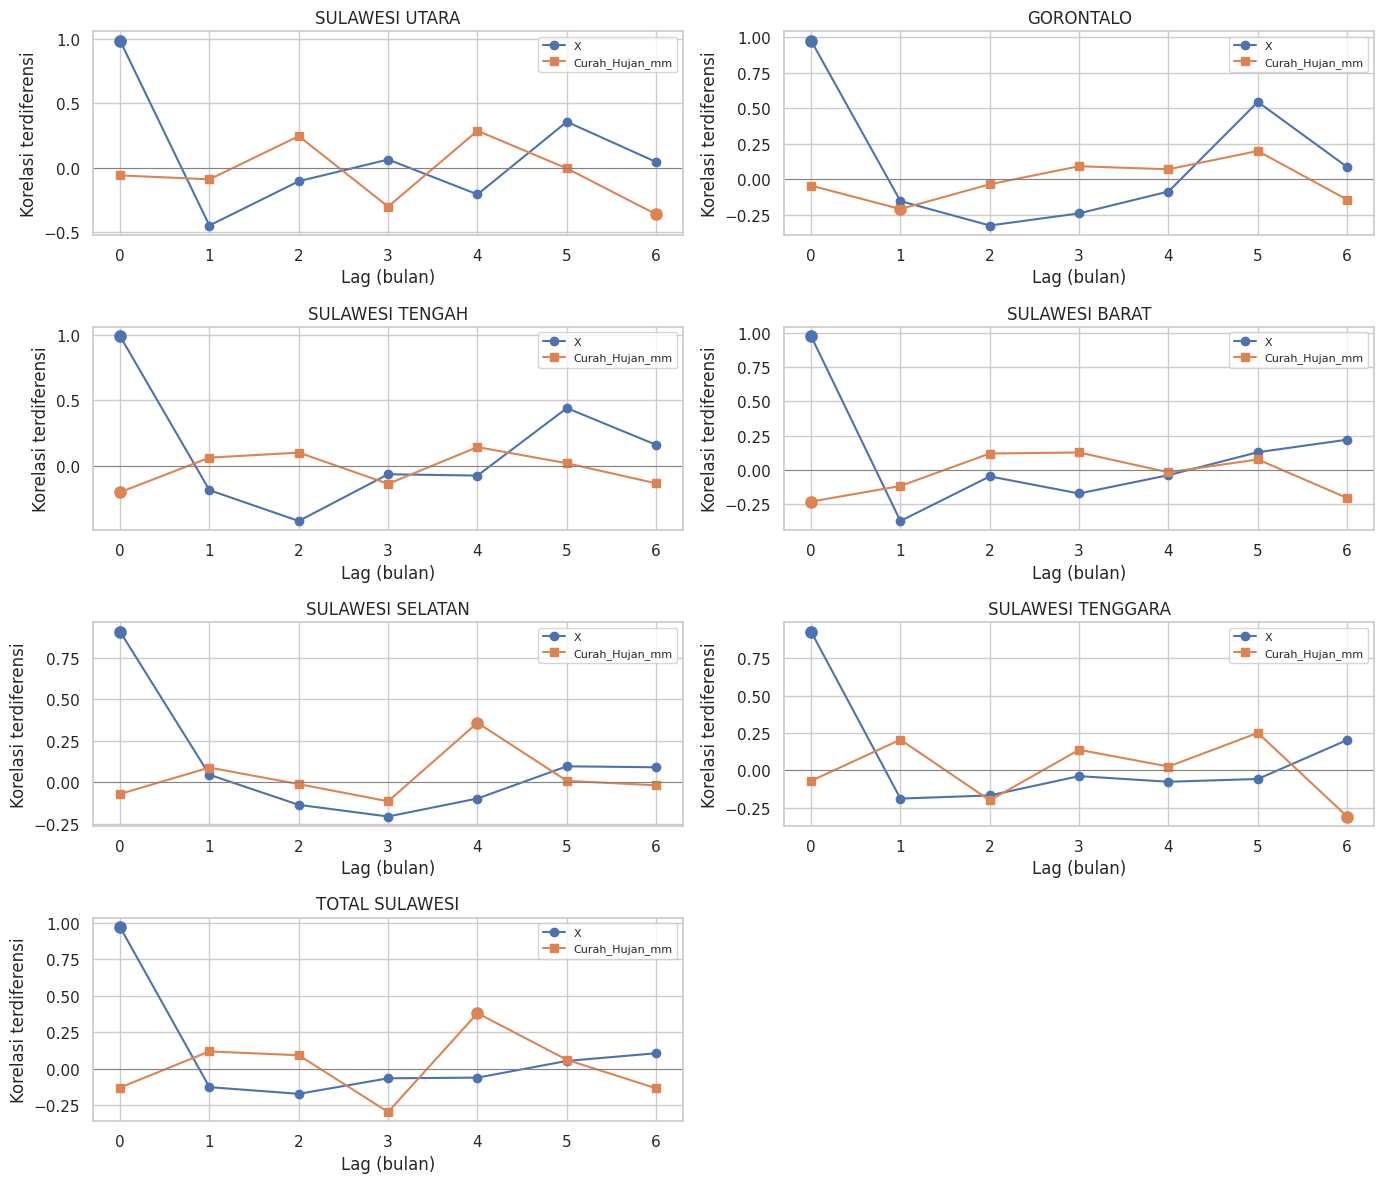

In [10]:
# Pilih lag terbaik pada rentang 0..MAX_LAG untuk KEDUA variabel eksogen.
# Korelasi dilakukan pada deret yang didifferencing 1 kali dan musiman 12 kali.
# Box-Cox Y sudah ditetapkan menggunakan data latih; X1 dan X2 memakai log1p.
kor=[]; lagrows=[]
for p in MODEL_PROV:
    d=pd.DataFrame({c:data[c][p].iloc[:-TEST] for c in [TARGET]+EXOG})
    kor.append({"Provinsi":p,"Corr Y-X lag 0":d[TARGET].corr(d["X"]),
                "Corr Y-Hujan lag 0":d[TARGET].corr(d["Curah_Hujan_mm"])})
    yy=transform_y(d[TARGET],p).diff(S).diff()
    for c in EXOG:
        xx=np.log1p(d[c]).diff(S).diff()
        for lag in range(MAX_LAG+1):
            r=yy.corr(xx.shift(lag))
            lagrows.append({"Provinsi":p,"Variabel":c,"Lag":lag,
                            "Corr_terdiferensi":r, "|Corr|":abs(r) if np.isfinite(r) else np.nan})
kor=pd.DataFrame(kor).set_index("Provinsi")
tabel_lag=pd.DataFrame(lagrows)
display(kor.round(3))
for c in EXOG:
    print(f"Korelasi silang Y terhadap {c} (lag 0–{MAX_LAG}):")
    display(tabel_lag[tabel_lag.Variabel==c].pivot(index="Provinsi",columns="Lag",values="Corr_terdiferensi").round(3))
lag_terpilih={}; selected_rows=[]
for p in MODEL_PROV:
    lag_terpilih[p]={}
    for c in EXOG:
        if AUTO_LAG:
            a=tabel_lag[(tabel_lag.Provinsi==p)&(tabel_lag.Variabel==c)].dropna(subset=["Corr_terdiferensi"])
            if a.empty: raise RuntimeError(f"CCF tidak dapat dihitung untuk {p} / {c}")
            row=a.loc[a["|Corr|"].idxmax()]
            lag=int(row.Lag); corr=float(row.Corr_terdiferensi)
        else:
            lag=int(LAG_MANUAL[c])
            a=tabel_lag[(tabel_lag.Provinsi==p)&(tabel_lag.Variabel==c)&(tabel_lag.Lag==lag)]
            corr=float(a.iloc[0].Corr_terdiferensi)
        assert 0<=lag<=START_LAG
        lag_terpilih[p][c]=lag
        selected_rows.append({"Provinsi":p,"Variabel":c,"Lag terpilih":lag,
                              "Korelasi pada lag":corr,
                              "Peringatan": "CCF lemah; uji ulang via validasi" if abs(corr)<MIN_ABS_CCF else ""})
tabel_lag_pilih=pd.DataFrame(selected_rows).set_index(["Provinsi","Variabel"])
print("Lag terpilih pada setiap provinsi dan variabel (berdasarkan data latih):")
display(tabel_lag_pilih.round(3))

fig,axes=plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    for c,mark in [("X","o"),("Curah_Hujan_mm","s")]:
        z=tabel_lag[(tabel_lag.Provinsi==p)&(tabel_lag.Variabel==c)]
        ax.plot(z.Lag,z.Corr_terdiferensi,marker=mark,label=c)
        ax.scatter(lag_terpilih[p][c],
                   z.loc[z.Lag==lag_terpilih[p][c],"Corr_terdiferensi"].iloc[0],s=65)
    ax.axhline(0,color="grey",lw=.7);ax.set_xticks(range(MAX_LAG+1))
    ax.set_title(p);ax.set_xlabel("Lag (bulan)");ax.set_ylabel("Korelasi terdiferensi")
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(MODEL_PROV):]: ax.axis("off")
plt.tight_layout();plt.show()


**Interpretasi:** `lag X = k₁` berarti luas panen bulan t−k₁ digunakan untuk menjelaskan produksi t; `lag hujan = k₂` demikian pula. **Keduanya diperlakukan sama**, dengan rentang kandidat 0–6. Lag 0 tetap bisa terpilih, tetapi **berdasarkan data, bukan ditetapkan di awal**. Korelasi terbesar setelah differencing adalah petunjuk eksploratif; CCF dapat dipengaruhi autokorelasi, trend, dan hubungan simultan, sehingga lag sebaiknya dikonfirmasi lewat validasi temporal tambahan. Korelasi absolut yang kecil diberi penanda, **bukan** otomatis dipaksa menjadi lag 0. Untuk peramalan ex-ante, variabel eksogen yang belum teramati tetap harus diproyeksikan.

## 3. Uji Stasioneritas dalam Rataan dan Penanganan Differencing

Sesudah menentukan kestabilan ragam dengan profil Box–Cox, uji ADF/KPSS dilakukan terhadap **Y pada skala hasil keputusan Box–Cox**. Empat kombinasi `d,D = (0,0), (1,0), (0,1), (1,1)` diperiksa **hanya pada data latih**.
- **ADF:** H₀ = terdapat akar unit. Nilai p < 0,05 mendukung stasioneritas.
- **KPSS:** H₀ = stasioner. Nilai p > 0,05 berarti tidak ada bukti cukup untuk menolak stasioneritas.

ADF/KPSS standar **tidak secara langsung** membuktikan ada/tidaknya akar unit musiman; cek ACF/PACF, AIC, dan diagnostik. Keputusan Box–Cox **tidak** menjamin ragam konstan; profil likelihood Box–Cox terutama mendasarkan estimasi λ pada asumsi normalitas data transformasi.

In [11]:
from statsmodels.tools.sm_exceptions import InterpolationWarning, ConvergenceWarning

def differencing(s,d,D):
    z=s.diff(S).dropna() if D else s.copy()
    return z.diff().dropna() if d else z

def uji(s):
    x=s.dropna()
    if len(x)<24 or x.nunique()<3:
        return {"ADF p":np.nan,"KPSS p":np.nan,"Lulus keduanya":False}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore",InterpolationWarning)
        try:a=adfuller(x,autolag="AIC")[1]
        except Exception:a=np.nan
        try:k=kpss(x,regression="c",nlags="auto")[1]
        except Exception:k=np.nan
    return {"ADF p":a,"KPSS p":k,
            "Lulus keduanya":bool(np.isfinite(a) and np.isfinite(k) and a<.05 and k>.05)}

tahap={};hasil=[];status_uji={}
for p in MODEL_PROV:
    z=transform_y(data[TARGET][p].iloc[START_LAG:-TEST],p)
    tahap[p]={}
    for d,D in [(0,0),(1,0),(0,1),(1,1)]:
        zz=differencing(z,d,D)
        tahap[p][(d,D)]=zz
        r=uji(zz)
        status_uji[(p,d,D)]=r
        hasil.append({"Provinsi":p,"d":d,"D":D,"N":len(zz),**r})
tabel_stas=pd.DataFrame(hasil).set_index(["Provinsi","d","D"])
display(tabel_stas.round(4))

N   ADF p  KPSS p  Lulus keduanya
Provinsi          d D                                    
SULAWESI UTARA    0 0  86  0.0045  0.1000            True
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.1480  0.0451           False
                  1 1  73  0.0561  0.1000           False
GORONTALO         0 0  86  0.0002  0.1000            True
                  1 0  85  0.0000  0.0952            True
                  0 1  74  0.0094  0.1000            True
                  1 1  73  0.0000  0.1000            True
SULAWESI TENGAH   0 0  86  0.0583  0.1000           False
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.0024  0.1000            True
                  1 1  73  0.1391  0.1000           False
SULAWESI BARAT    0 0  86  0.3015  0.1000           False
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.1820  0.1000           False
                  1 1  73  0.0091  0.1000            True
SULAWESI SELATAN  0 0  86  0.0826  0.1000           False
                  1 0  85  0.0001  0.1000            True
                  0 1  74  0.0000  0.1000            True
                  1 1  73  0.0000  0.1000            True
SULAWESI TENGGARA 0 0  86  0.9222  0.1000           False
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.0000  0.1000            True
                  1 1  73  0.0421  0.1000            True
TOTAL SULAWESI    0 0  86  0.1840  0.1000           False
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.0040  0.1000            True
                  1 1  73  0.0333  0.0417           False

### 3.1 Menentukan d dan D secara otomatis

In [12]:
# Parsimoni: D tidak ditetapkan otomatis hanya dari kekuatan musiman.
# Bila ada beberapa kombinasi lulus ADF dan KPSS, kekuatan STL hanya menjadi
# petunjuk preferensi antara (0,1) dan (1,0); utamakan (0,0) jika sudah cukup.
orde_dD={}
for p in MODEL_PROV:
    prioritas=([(0,0),(0,1),(1,0),(1,1)] if strength[p]>=.64
               else [(0,0),(1,0),(0,1),(1,1)])
    valid=[(d,D) for d,D in prioritas if status_uji[(p,d,D)]["Lulus keduanya"]]
    if valid:
        chosen=valid[0];catatan="ADF/KPSS mendukung (heuristik)"
    else:
        by_adf=[(d,D) for d,D in prioritas if status_uji[(p,d,D)]["ADF p"]<.05]
        chosen=by_adf[0] if by_adf else (1,1)
        catatan="ADF/KPSS konflik; periksa manual"
    orde_dD[p]=chosen
    print(f"{p:20s} d={chosen[0]} D={chosen[1]} | {catatan}")
tabel_orde=pd.DataFrame(orde_dD,index=["d","D"]).T

SULAWESI UTARA       d=0 D=0 | ADF/KPSS mendukung (heuristik)
GORONTALO            d=0 D=0 | ADF/KPSS mendukung (heuristik)
SULAWESI TENGAH      d=0 D=1 | ADF/KPSS mendukung (heuristik)
SULAWESI BARAT       d=1 D=0 | ADF/KPSS mendukung (heuristik)
SULAWESI SELATAN     d=0 D=1 | ADF/KPSS mendukung (heuristik)
SULAWESI TENGGARA    d=0 D=1 | ADF/KPSS mendukung (heuristik)
TOTAL SULAWESI       d=0 D=1 | ADF/KPSS mendukung (heuristik)


**Catatan:** penentuan d dan D di atas adalah prosedur heuristik awal pada data latih, bukan keputusan universal. Kekuatan musiman STL bukan uji akar unit musiman. Periksa ACF/PACF dan diagnostik residual, dan bandingkan kombinasi d,D alternatif jika terdapat ketidakjelasan.

### 3.2 Visual differencing + identifikasi ACF/PACF

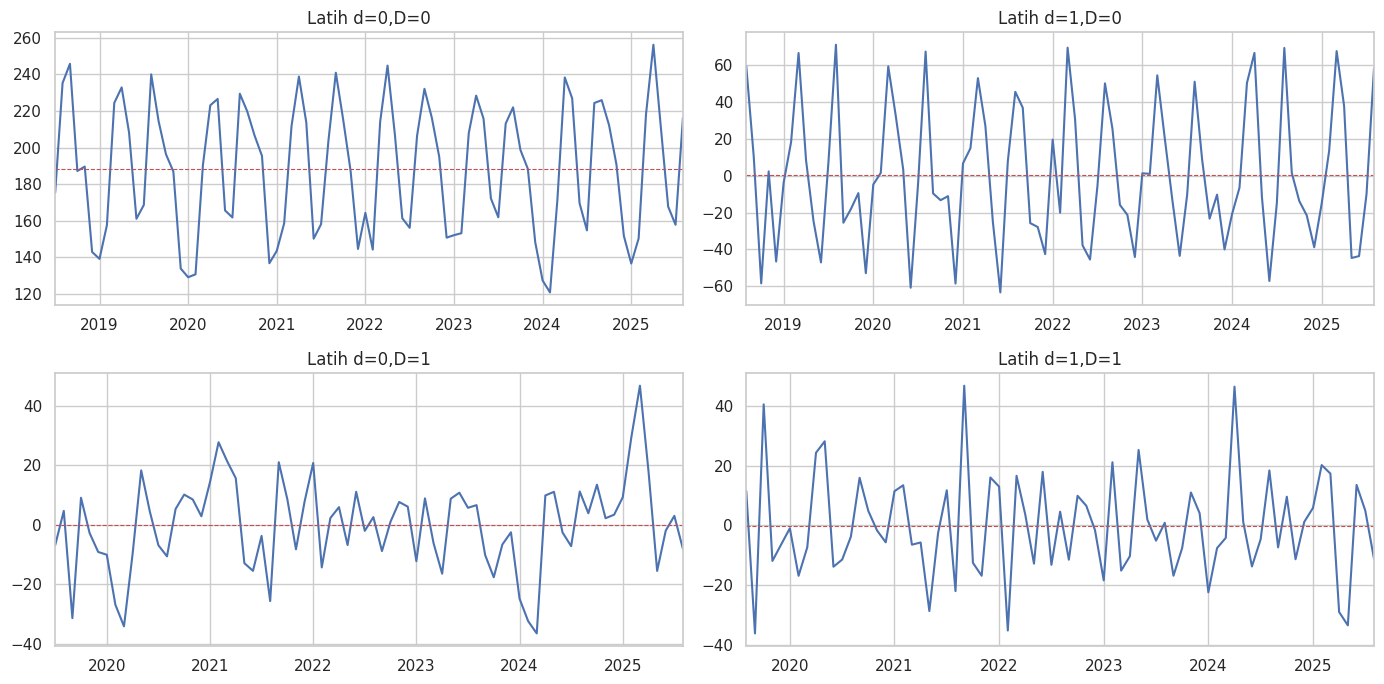

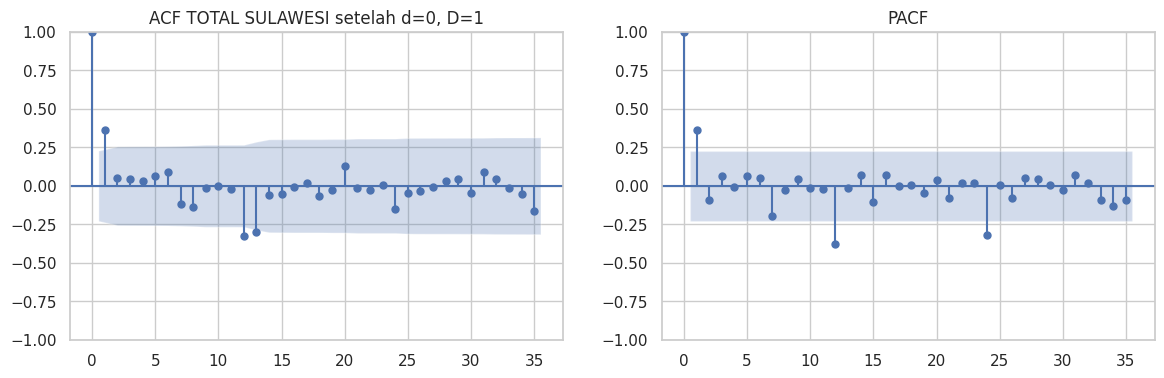

In [13]:
p=TOTAL
fig,axes=plt.subplots(2,2,figsize=(14,7))
for ax,(d,D) in zip(axes.ravel(),[(0,0),(1,0),(0,1),(1,1)]):
    s=tahap[p][(d,D)]
    s.plot(ax=ax);ax.axhline(s.mean(),ls="--",lw=.8,color="r")
    ax.set_title(f"Latih d={d},D={D}")
plt.tight_layout();plt.show()
d,D=orde_dD[p]
z=tahap[p][(d,D)]
nlags=min(36,len(z)//2-2)
fig,axes=plt.subplots(1,2,figsize=(14,4))
plot_acf(z,lags=nlags,ax=axes[0]);plot_pacf(z,lags=nlags,ax=axes[1],method="ywm")
axes[0].set_title(f"ACF {p} setelah d={d}, D={D}");axes[1].set_title("PACF")
plt.show()

Gunakan ACF/PACF di atas sebagai petunjuk: lonjakan pada lag 1-2 menunjukkan p, q non-musiman; lonjakan pada lag 12, 24 menunjukkan P, Q musiman.

## 4. Identifikasi dan Estimasi Model

Grid model menggunakan p,q = 0,1,2 dan P,Q = 0,1 dengan d,D yang dipilih pada **data latih**. Perbandingan SARIMA dan SARIMAX menggunakan rentang waktu latih identik, **Y dan transformasi yang sama**, serta syarat konvergensi. Data awal sebanyak 6 bulan dipotong dari semua model untuk ketersediaan lag eksogen dan keseimbangan perbandingan. **Lag X dan lag curah hujan** mengikuti pemilihan lag eksploratif sebelumnya.

In [14]:
# Eksogen historis dengan lag terpilih untuk kedua variabel.
# Transformasi log1p eksogen tidak berkaitan dengan keputusan Box–Cox pada Y.
def exog_hist(p):
    return pd.DataFrame({
        "log1p_luas_panen_lag":np.log1p(data["X"][p].shift(lag_terpilih[p]["X"])),
        "log1p_hujan_lag":np.log1p(data["Curah_Hujan_mm"][p].shift(lag_terpilih[p]["Curah_Hujan_mm"]))
    },index=data[TARGET].index)

def split(p,use_exog):
    y=transform_y(data[TARGET][p].iloc[START_LAG:],p)
    ex=exog_hist(p).loc[y.index] if use_exog else None
    assert not y.isna().any()
    if ex is not None: assert not ex.isna().any().any()
    return y,ex

def fit(y,ex,order,sorder,maxiter=MAX_ITER_GRID):
    trend="n" if (order[1] or sorder[1]) else "c"
    m=SARIMAX(y,exog=ex,order=order,seasonal_order=sorder,
              trend=trend,enforce_stationarity=False,enforce_invertibility=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore",ConvergenceWarning)
        warnings.simplefilter("ignore",RuntimeWarning)
        return m.fit(disp=False,maxiter=maxiter)

def grid_search(y,ex,d,D,pmax=2,qmax=2,Pmax=1,Qmax=1):
    tabel=[];candidates=[]
    for p_,q_,P_,Q_ in itertools.product(range(pmax+1),range(qmax+1),range(Pmax+1),range(Qmax+1)):
        order=(p_,d,q_);so=(P_,D,Q_,S)
        try:
            r=fit(y,ex,order,so)
            conv=bool(r.mle_retvals.get("converged",False))
            tabel.append({"order":str(order),"seasonal":str(so),"AIC":r.aic,
                          "BIC":r.bic,"Konvergen":conv})
            if conv and np.isfinite(r.aic): candidates.append((r.aic,order,so,r))
        except (ValueError,np.linalg.LinAlgError,OverflowError,ZeroDivisionError):continue
    if not candidates:raise RuntimeError("Tidak ada model konvergen; periksa data atau tingkatkan iterasi")
    aic,order,so,res=min(candidates,key=lambda c:c[0])
    return (order,so,aic,res),pd.DataFrame(tabel).sort_values("AIC")

pilihan={}; model_train={}; grid_tabel={};order_rows=[]
for p in MODEL_PROV:
    d,D=orde_dD[p]
    for var,ue in [("SARIMA",False),("SARIMAX",True)]:
        y,ex=split(p,ue)
        tr_y=y.iloc[:-TEST];tr_ex=ex.iloc[:-TEST] if ex is not None else None
        best,tab=grid_search(tr_y,tr_ex,d,D)
        pilihan[(p,var)]=best[:3]
        model_train[(p,var)]=best[3]
        grid_tabel[(p,var)]=tab
        order_rows.append({"Provinsi":p,"Model":var,"order":str(best[0]),"seasonal":str(best[1]),
                           "AIC latih":best[2],"Kandidat konvergen":int(tab["Konvergen"].sum())})
        print(f"{p:19s} {var:7s} {best[0]} {best[1]} | AIC={best[2]:.2f}")
tabel_pilihan=pd.DataFrame(order_rows).set_index(["Provinsi","Model"])
display(tabel_pilihan)

SULAWESI UTARA      SARIMA  (0, 0, 2) (1, 0, 1, 12) | AIC=241.81
SULAWESI UTARA      SARIMAX (1, 0, 0) (0, 0, 0, 12) | AIC=28.44
GORONTALO           SARIMA  (2, 0, 2) (1, 0, 1, 12) | AIC=592.67
GORONTALO           SARIMAX (0, 0, 2) (0, 0, 1, 12) | AIC=406.22
SULAWESI TENGAH     SARIMA  (2, 0, 2) (1, 1, 1, 12) | AIC=665.26
SULAWESI TENGAH     SARIMAX (0, 0, 2) (0, 1, 1, 12) | AIC=487.61
SULAWESI BARAT      SARIMA  (0, 1, 2) (1, 0, 1, 12) | AIC=509.21
SULAWESI BARAT      SARIMAX (0, 1, 2) (1, 0, 1, 12) | AIC=287.60
SULAWESI SELATAN    SARIMA  (2, 0, 2) (0, 1, 1, 12) | AIC=491.12
SULAWESI SELATAN    SARIMAX (2, 0, 2) (0, 1, 1, 12) | AIC=373.55
SULAWESI TENGGARA   SARIMA  (0, 0, 2) (0, 1, 1, 12) | AIC=569.16
SULAWESI TENGGARA   SARIMAX (1, 0, 2) (0, 1, 1, 12) | AIC=450.91
TOTAL SULAWESI      SARIMA  (1, 0, 2) (0, 1, 1, 12) | AIC=466.42
TOTAL SULAWESI      SARIMAX (1, 0, 2) (1, 1, 1, 12) | AIC=299.48


order       seasonal   AIC latih  \
Provinsi          Model                                           
SULAWESI UTARA    SARIMA   (0, 0, 2)  (1, 0, 1, 12)  241.814750   
                  SARIMAX  (1, 0, 0)  (0, 0, 0, 12)   28.438772   
GORONTALO         SARIMA   (2, 0, 2)  (1, 0, 1, 12)  592.665732   
                  SARIMAX  (0, 0, 2)  (0, 0, 1, 12)  406.222861   
SULAWESI TENGAH   SARIMA   (2, 0, 2)  (1, 1, 1, 12)  665.264185   
                  SARIMAX  (0, 0, 2)  (0, 1, 1, 12)  487.611682   
SULAWESI BARAT    SARIMA   (0, 1, 2)  (1, 0, 1, 12)  509.213359   
                  SARIMAX  (0, 1, 2)  (1, 0, 1, 12)  287.595910   
SULAWESI SELATAN  SARIMA   (2, 0, 2)  (0, 1, 1, 12)  491.120108   
                  SARIMAX  (2, 0, 2)  (0, 1, 1, 12)  373.548837   
SULAWESI TENGGARA SARIMA   (0, 0, 2)  (0, 1, 1, 12)  569.157957   
                  SARIMAX  (1, 0, 2)  (0, 1, 1, 12)  450.912973   
TOTAL SULAWESI    SARIMA   (1, 0, 2)  (0, 1, 1, 12)  466.416685   
                  SARIMAX  (1, 0, 2)  (1, 1, 1, 12)  299.483929   

                           Kandidat konvergen  
Provinsi          Model                        
SULAWESI UTARA    SARIMA                   33  
                  SARIMAX                  31  
GORONTALO         SARIMA                   34  
                  SARIMAX                  28  
SULAWESI TENGAH   SARIMA                   36  
                  SARIMAX                  35  
SULAWESI BARAT    SARIMA                   36  
                  SARIMAX                  35  
SULAWESI SELATAN  SARIMA                   36  
                  SARIMAX                  36  
SULAWESI TENGGARA SARIMA                   36  
                  SARIMAX                  36  
TOTAL SULAWESI    SARIMA                   36  
                  SARIMAX                  36

## 5. Evaluasi 12 Bulan Terakhir (Holdout)

Dibandingkan empat pendekatan: (1) SARIMA tanpa eksogen, (2) **SARIMAX-skenario** dengan eksogen diproyeksikan hanya dari data sebelum holdout, (3) **SARIMAX-kondisional** dengan eksogen aktual yang hanya mungkin diketahui sesudah waktu berjalan, dan (4) naif musiman. Nilai ramalan SARIMA/SARIMAX dibalik dari skala Box–Cox ke **satuan produksi padi asli** sebelum evaluasi. **Hanya (1), (2) dan (4)** yang tepat untuk pembandingan ramalan ex-ante.

In [15]:
def metrik(a,f):
    a=np.asarray(a,dtype=float);f=np.asarray(f,dtype=float)
    assert np.isfinite(a).all() and np.isfinite(f).all()
    ae=np.abs(a-f)
    denom=np.abs(a)+np.abs(f)
    smape=100*np.mean(np.divide(2*ae,denom,out=np.zeros_like(ae),where=denom>0))
    mape=100*np.mean(ae/a) if (a>0).all() else np.nan
    return {"MAE":np.mean(ae),"RMSE":np.sqrt(np.mean((a-f)**2)),
            "MAPE (%)":mape,"sMAPE (%)":smape}

def kembali(v,p):
    """Invers transformasi Y per provinsi pada skala asli (median kondisional)."""
    a=np.asarray(v,dtype=float)
    if boxcox_status[p]["Transformasi"]=="Box-Cox":
        lam=boxcox_status[p]["Lambda_dipakai"]
        shift=boxcox_status[p]["Shift"]
        # Invers hanya sah di domain 1 + lambda*z > 0.
        valid=(1+lam*a)>0 if abs(lam)>1e-10 else np.ones_like(a,dtype=bool)
        if not valid.all():
            warnings.warn(f"{p}: ada prediksi di luar domain invers Box-Cox; ditandai NaN. Tinjau orde/model.")
        z=np.where(valid,a,np.nan)
        result=inv_boxcox(z,lam)-shift
    else:
        result=a
    return np.maximum(result,0.0)

def exog_skenario(p,origin,future_dates):
    # Proyeksi X dan hujan hanya memakai nilai yang SUDAH diketahui pada origin.
    # Nilai bulanan merupakan rata-rata kalender 36 bulan sebelumnya.
    hist=seri[p].loc[:origin,EXOG]
    tail=hist.iloc[-36:]
    assert len(tail)==36,"Perlu sekurangnya 36 bulan historis untuk eksogen"
    future=pd.DataFrame(index=future_dates,columns=EXOG,dtype=float)
    for c in EXOG:
        clim=tail[c].groupby(tail.index.month).mean()
        future[c]=[clim[m] for m in future_dates.month]
    # Gabung supaya hujan lag 1..6 pada awal horizon tetap mengambil
    # hujan yang sudah diketahui sebelum origin.
    full=pd.concat([hist,future])
    ex=pd.DataFrame({
        "log1p_luas_panen_lag":np.log1p(full["X"].shift(lag_terpilih[p]["X"])).reindex(future_dates),
        "log1p_hujan_lag":np.log1p(full["Curah_Hujan_mm"].shift(lag_terpilih[p]["Curah_Hujan_mm"])).reindex(future_dates)
    },index=future_dates)
    assert not ex.isna().any().any(),"Fitur eksogen masa depan tidak lengkap"
    return ex

idx_test=data[TARGET].index[-TEST:]
origin=data[TARGET].index[-TEST-1]
eval_rows=[];fc_test={}
for p in MODEL_PROV:
    ya=data[TARGET][p].loc[idx_test]
    sarima=model_train[(p,"SARIMA")]
    sarimax=model_train[(p,"SARIMAX")]
    f_sarima=kembali(sarima.get_forecast(TEST).predicted_mean,p)
    f_skenario=kembali(sarimax.get_forecast(TEST,exog=exog_skenario(p,origin,idx_test)).predicted_mean,p)
    f_cond=kembali(sarimax.get_forecast(TEST,exog=exog_hist(p).loc[idx_test]).predicted_mean,p)
    f_naif=data[TARGET][p].shift(S).loc[idx_test].to_numpy()
    for var,f in [("SARIMA",f_sarima),("SARIMAX-skenario",f_skenario),
                  ("SARIMAX-kondisional",f_cond),("Naif musiman",f_naif)]:
        fc_test[(p,var)]=pd.Series(f,index=idx_test)
        eval_rows.append({"Provinsi":p,"Model":var,**metrik(ya,f)})
evaluasi=pd.DataFrame(eval_rows).set_index(["Provinsi","Model"])
display(evaluasi.round(2))

# Hanya peramalan yang mungkin ex-ante dipakai untuk pemilihan model operasional.
model_pilih={};winner_rows=[]
for p in MODEL_PROV:
    a=evaluasi.loc[p]
    kandidat=a.loc[["SARIMA","SARIMAX-skenario"],"MAE"]
    win=kandidat.idxmin()
    model_pilih[p]="SARIMAX" if win=="SARIMAX-skenario" else "SARIMA"
    winner_rows.append({"Provinsi":p,"Model dipilih":model_pilih[p],
                        "MAE terpilih":kandidat.min(),
                        "MAE naif musiman":a.loc["Naif musiman","MAE"],
                        "Naif lebih baik?":bool(a.loc["Naif musiman","MAE"]<kandidat.min())})
pemenang=pd.DataFrame(winner_rows).set_index("Provinsi")
display(pemenang.round(2))

MAE       RMSE  MAPE (%)  \
Provinsi          Model                                                 
SULAWESI UTARA    SARIMA                 3730.41    4470.71     15.54   
                  SARIMAX-skenario       2262.18    3259.53      9.62   
                  SARIMAX-kondisional    1763.04    2125.35      8.22   
                  Naif musiman           3528.41    4726.82     15.93   
GORONTALO         SARIMA                12944.32   14718.26    103.61   
                  SARIMAX-skenario       7155.01    9569.85     43.85   
                  SARIMAX-kondisional    2361.64    3447.89     12.11   
                  Naif musiman          10100.73   14921.25     42.50   
SULAWESI TENGAH   SARIMA                22439.30   24757.37     31.15   
                  SARIMAX-skenario      20528.35   24063.97     29.86   
                  SARIMAX-kondisional    5294.72    7987.99      5.83   
                  Naif musiman          24481.14   28140.67     39.06   
SULAWESI BARAT    SARIMA                10218.86   13103.10     27.63   
                  SARIMAX-skenario       8459.17   10266.72     24.33   
                  SARIMAX-kondisional    3137.70    3554.65      9.33   
                  Naif musiman          10734.04   12001.39     34.92   
SULAWESI SELATAN  SARIMA                87631.89  121578.64     19.79   
                  SARIMAX-skenario      93024.95  125567.87     21.33   
                  SARIMAX-kondisional   36726.37   53220.91      6.97   
                  Naif musiman         107195.77  148330.23     21.79   
SULAWESI TENGGARA SARIMA                10795.39   15128.45     20.02   
                  SARIMAX-skenario       9213.90   13400.76     16.79   
                  SARIMAX-kondisional    3693.02    5777.09      6.10   
                  Naif musiman           8160.03   10471.04     15.68   
TOTAL SULAWESI    SARIMA               119874.45  160334.56     15.59   
                  SARIMAX-skenario     119383.72  152295.66     16.53   
                  SARIMAX-kondisional   20830.80   28010.60      3.16   
                  Naif musiman         109899.01  147427.38     13.93   

                                       sMAPE (%)  
Provinsi          Model                           
SULAWESI UTARA    SARIMA                   16.43  
                  SARIMAX-skenario         10.63  
                  SARIMAX-kondisional       8.72  
                  Naif musiman             15.83  
GORONTALO         SARIMA                   69.47  
                  SARIMAX-skenario         34.70  
                  SARIMAX-kondisional      13.49  
                  Naif musiman             36.79  
SULAWESI TENGAH   SARIMA                   34.34  
                  SARIMAX-skenario         30.74  
                  SARIMAX-kondisional       6.02  
                  Naif musiman             37.51  
SULAWESI BARAT    SARIMA                   30.98  
                  SARIMAX-skenario         28.16  
                  SARIMAX-kondisional       9.20  
                  Naif musiman             40.56  
SULAWESI SELATAN  SARIMA                   21.64  
                  SARIMAX-skenario         22.76  
                  SARIMAX-kondisional       7.23  
                  Naif musiman             24.75  
SULAWESI TENGGARA SARIMA                   23.55  
                  SARIMAX-skenario         17.55  
                  SARIMAX-kondisional       6.19  
                  Naif musiman             15.12  
TOTAL SULAWESI    SARIMA                   16.98  
                  SARIMAX-skenario         17.48  
                  SARIMAX-kondisional       3.25  
                  Naif musiman             14.66

,Model dipilih,MAE terpilih,MAE naif musiman,Naif lebih baik?
Provinsi,,,,
SULAWESI UTARA,SARIMAX,2262.18,3528.41,False
GORONTALO,SARIMAX,7155.01,10100.73,False
SULAWESI TENGAH,SARIMAX,20528.35,24481.14,False
SULAWESI BARAT,SARIMAX,8459.17,10734.04,False
SULAWESI SELATAN,SARIMA,87631.89,107195.77,False
SULAWESI TENGGARA,SARIMAX,9213.90,8160.03,True
TOTAL SULAWESI,SARIMAX,119383.72,109899.01,True


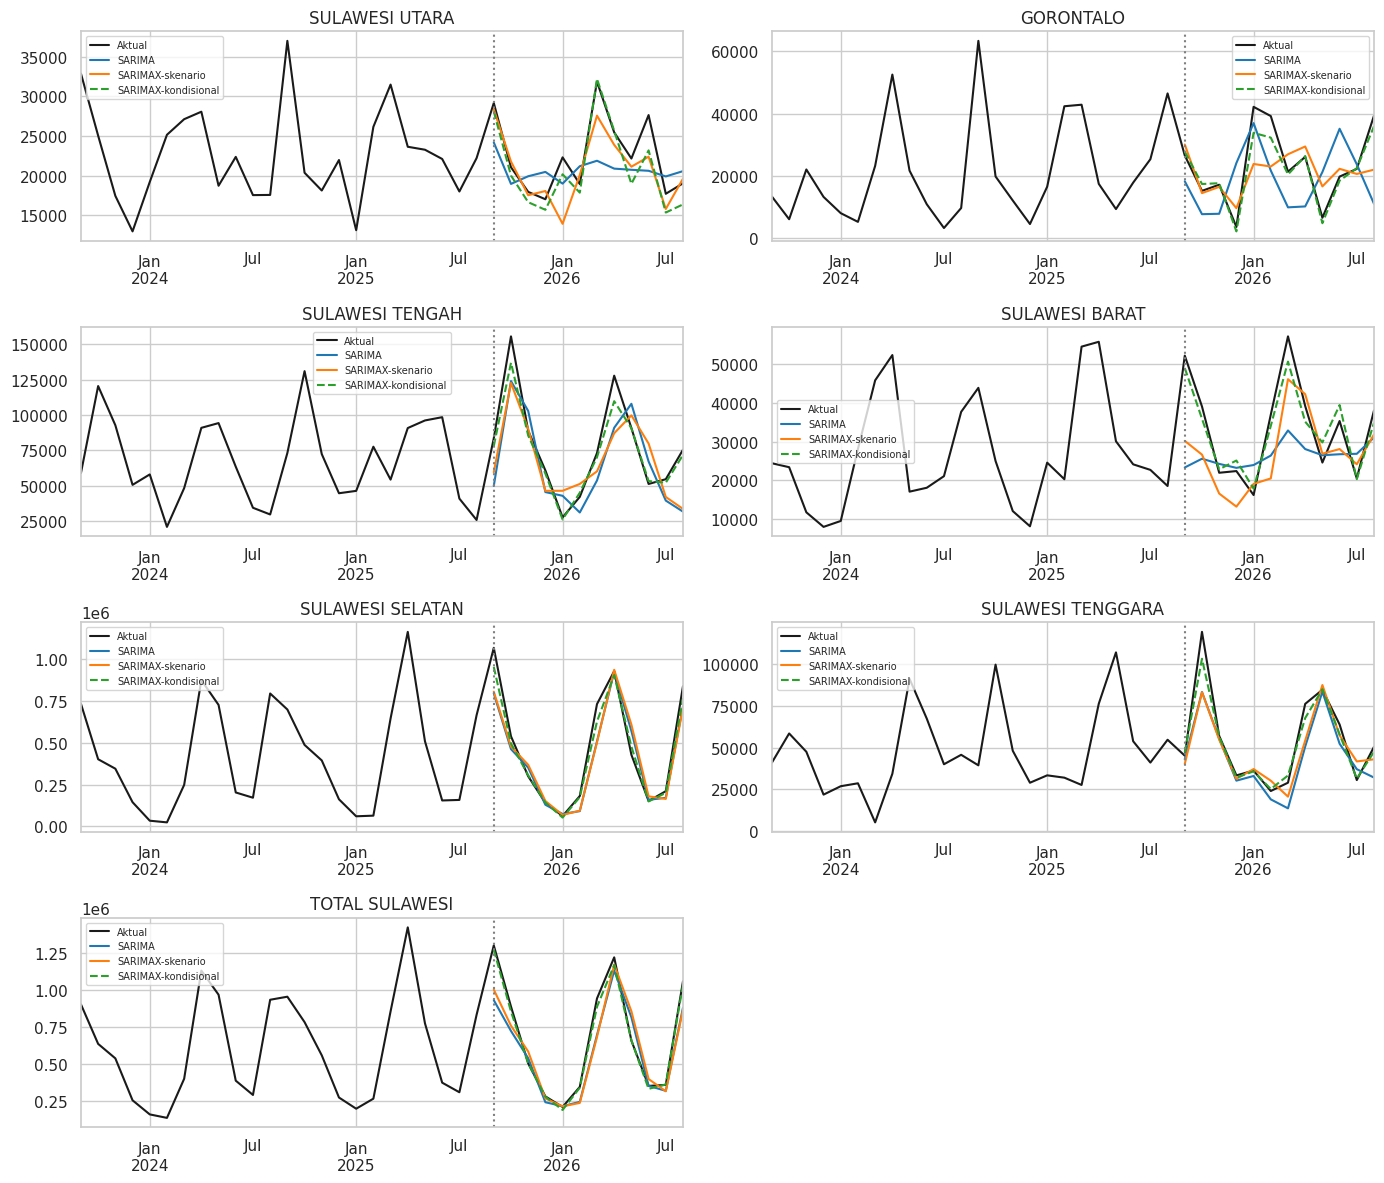

In [16]:
fig,axes=plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    data[TARGET][p].iloc[-36:].plot(ax=ax,color="k",label="Aktual")
    for nama,c in [("SARIMA","tab:blue"),("SARIMAX-skenario","tab:orange"),
                   ("SARIMAX-kondisional","tab:green")]:
        fc_test[(p,nama)].plot(ax=ax,color=c,ls="--" if nama=="SARIMAX-kondisional" else "-",label=nama)
    ax.axvline(idx_test[0],color="gray",ls=":");ax.set_title(p);ax.legend(fontsize=7)
for ax in axes.ravel()[len(MODEL_PROV):]:ax.axis("off")
plt.tight_layout();plt.show()

**Kesimpulan dari holdout:** Bandingkan MAE, RMSE, dan sMAPE **SARIMA vs SARIMAX-skenario**, bukan SARIMA vs SARIMAX-kondisional, untuk menilai kemampuan ramalan operasional. Metrik SARIMAX-kondisional dipaparkan hanya untuk menunjukkan hubungan bersyarat pada eksogen aktual. Jika naif musiman lebih baik daripada dua metode, nyatakan secara eksplisit. Satu pemisahan latih-uji tetap tidak sekuat validasi bergulir (*rolling-origin*) dan bukan jaminan kinerja masa depan.

## 6. Diagnostik Residual

N residual  Konvergen  LB p lag 12  LB p lag 24  \
Provinsi          Model                                                      
SULAWESI UTARA    SARIMA           71       True       0.0716       0.0802   
                  SARIMAX          74       True       0.5543       0.8873   
GORONTALO         SARIMA           71       True       0.0714       0.1411   
                  SARIMAX          71       True       0.2721       0.5101   
SULAWESI TENGAH   SARIMA           59       True       0.1208       0.6863   
                  SARIMAX          59       True       0.7340       0.9688   
SULAWESI BARAT    SARIMA           70       True       0.0404       0.0341   
                  SARIMAX          70       True       0.1416       0.5561   
SULAWESI SELATAN  SARIMA           59       True       0.4021       0.7789   
                  SARIMAX          59       True       0.2677       0.4233   
SULAWESI TENGGARA SARIMA           59       True       0.6387       0.7135   
                  SARIMAX          59       True       0.4309       0.3058   
TOTAL SULAWESI    SARIMA           59       True       0.1093       0.3669   
                  SARIMAX          59       True       0.0608       0.2907   

                             JB p  
Provinsi          Model            
SULAWESI UTARA    SARIMA   0.6250  
                  SARIMAX  0.0004  
GORONTALO         SARIMA   0.8364  
                  SARIMAX  0.0110  
SULAWESI TENGAH   SARIMA   0.4004  
                  SARIMAX  0.3685  
SULAWESI BARAT    SARIMA   0.2369  
                  SARIMAX  0.0000  
SULAWESI SELATAN  SARIMA   0.1133  
                  SARIMAX  0.0627  
SULAWESI TENGGARA SARIMA   0.5606  
                  SARIMAX  0.2092  
TOTAL SULAWESI    SARIMA   0.1295  
                  SARIMAX  0.9277

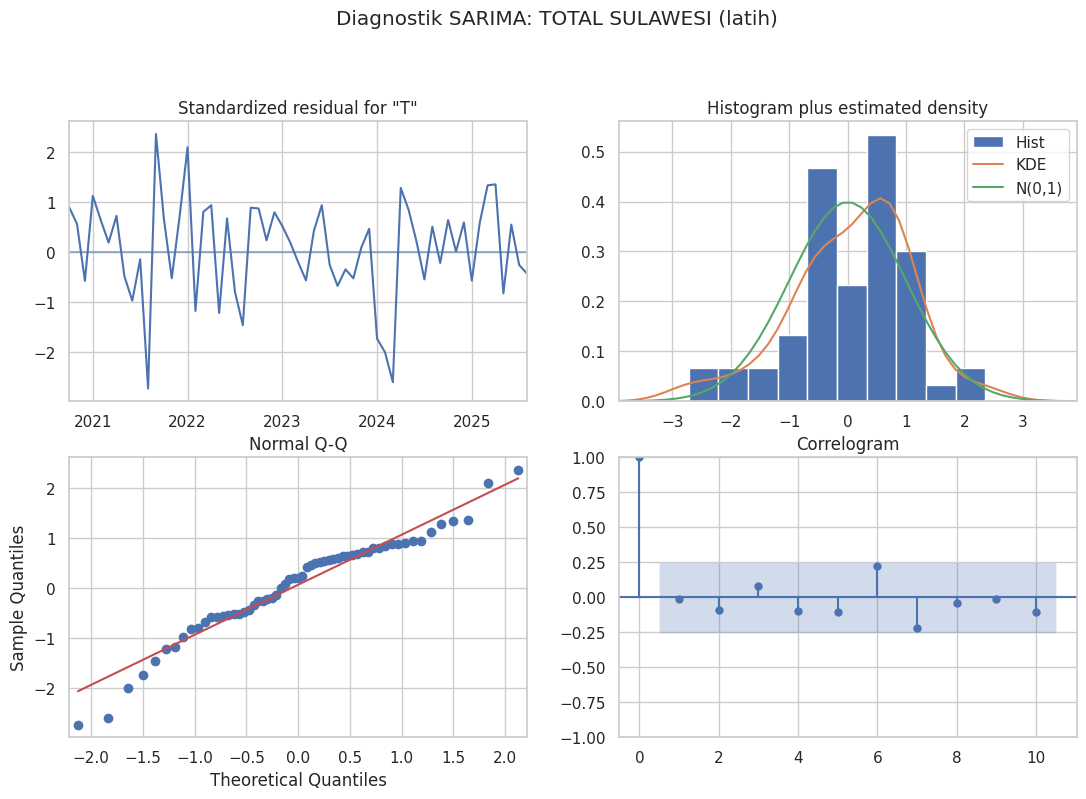

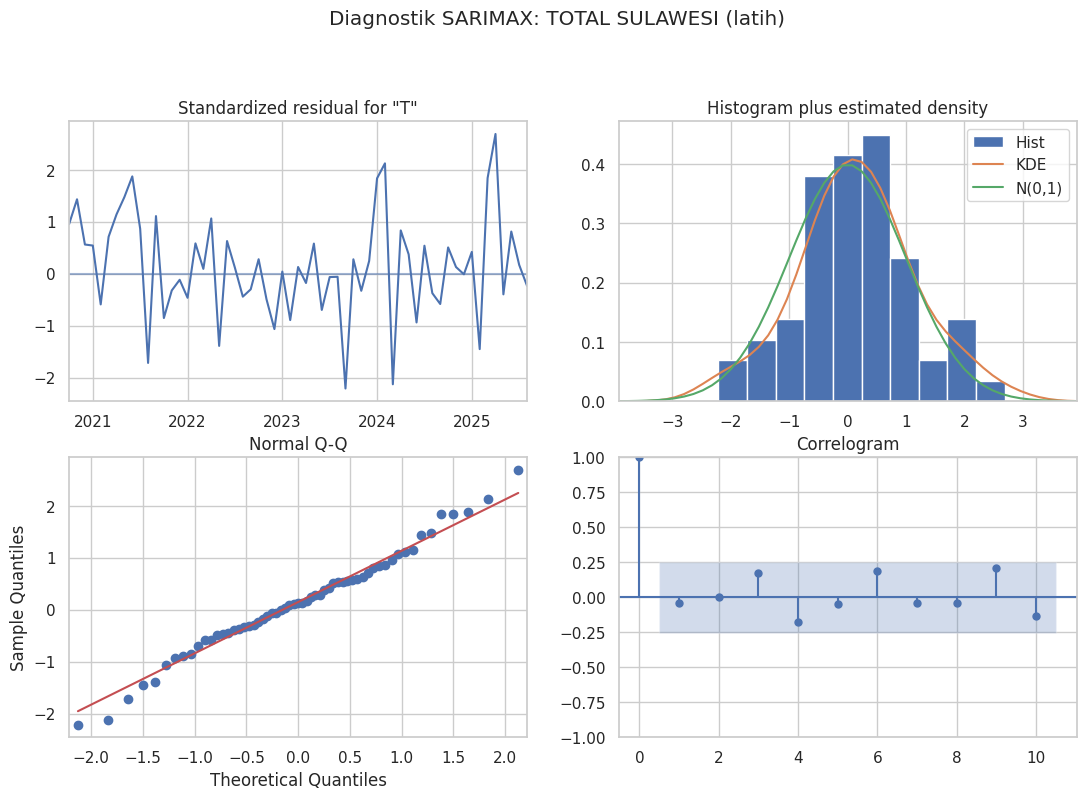

In [17]:
def diagnostik(r,p,var):
    # standardized_forecasts_error mengurangi persoalan skala dan varians yang berubah.
    burn=max(S,int(getattr(r,"loglikelihood_burn",0)))
    res=np.asarray(r.filter_results.standardized_forecasts_error[0],dtype=float)[burn:]
    res=res[np.isfinite(res)]
    order,sorder,_=pilihan[(p,var)]
    # Derajat bebas Ljung-Box untuk bagian AR/MA reguler dan musiman.
    df_model=order[0]+order[2]+sorder[0]+sorder[2]
    use_lags=[l for l in [12,24] if l>df_model and l<len(res)]
    lb=acorr_ljungbox(res,lags=use_lags,model_df=df_model,return_df=True) if use_lags else None
    return {"Provinsi":p,"Model":var,"N residual":len(res),
            "Konvergen":bool(r.mle_retvals.get("converged",False)),
            "LB p lag 12":lb.loc[12,"lb_pvalue"] if lb is not None and 12 in lb.index else np.nan,
            "LB p lag 24":lb.loc[24,"lb_pvalue"] if lb is not None and 24 in lb.index else np.nan,
            "JB p":jarque_bera(res)[1] if len(res)>8 and np.std(res)>0 else np.nan}

dg=pd.DataFrame([diagnostik(model_train[(p,var)],p,var) for p in MODEL_PROV
                 for var in ["SARIMA","SARIMAX"]]).set_index(["Provinsi","Model"])
display(dg.round(4))
for var in ["SARIMA","SARIMAX"]:
    r=model_train[(TOTAL,var)]
    r.plot_diagnostics(figsize=(13,8));plt.suptitle(f"Diagnostik {var}: {TOTAL} (latih)",y=1.02);plt.show()

**Interpretasi:** Ljung-Box p > 0,05 = **tidak cukup bukti** autokorelasi hingga lag tersebut, bukan bukti residual pasti independen. Jarque-Bera p > 0,05 = normalitas residual tidak ditolak. Ljung-Box telah menyesuaikan derajat bebas untuk p+q+P+Q. Jika p kecil, model masih menyisakan pola dan perlu perbaikan; jangan menyatakan lolos diagnostik untuk semua provinsi. Semua angka dihitung pada data latih.

## 7. Peramalan 12 Bulan ke Depan

Pilih antara SARIMA dan SARIMAX-skenario berdasarkan **MAE holdout**, lalu latih ulang pada seluruh pengamatan dengan orde, lag, dan λ **yang dipilih hanya menggunakan data latih semula** agar penilaian historis tidak bocor. Ramalkan 12 bulan ke depan; bila SARIMAX terpilih, proyeksi eksogen disusun dari rerata bulan kalender 36 bulan terakhir. Terakhir lakukan invers Box–Cox berdasarkan λ dan shift yang telah disimpan. Invers terhadap nilai ramalan menghasilkan **median kondisional**, bukan mean yang bebas bias.

**Skenario eksogen:** luas panen dan curah hujan masa depan belum diketahui. Skenario yang digunakan adalah rerata masing-masing bulan kalender dari 36 bulan terakhir sebelum origin. Untuk lag terpilih k>0, bulan awal horizon dapat memakai eksogen historis yang benar-benar sudah diketahui; bulan lainnya memakai skenario. Ini **bukan ramalan resmi** luas panen/curah hujan. Selang prediksi hanya bersifat kondisional pada skenario eksogen, dan tidak memuat ketidakpastian skenario atau estimasi parameter model.

Periode ramalan: 2026-09 s.d. 2027-08


,Metode,Konvergen full
Provinsi,,
SULAWESI UTARA,SARIMAX,True
GORONTALO,SARIMAX,True
SULAWESI TENGAH,SARIMAX,True
SULAWESI BARAT,SARIMAX,True
SULAWESI SELATAN,SARIMA,True
SULAWESI TENGGARA,SARIMAX,True
TOTAL SULAWESI,SARIMAX,True


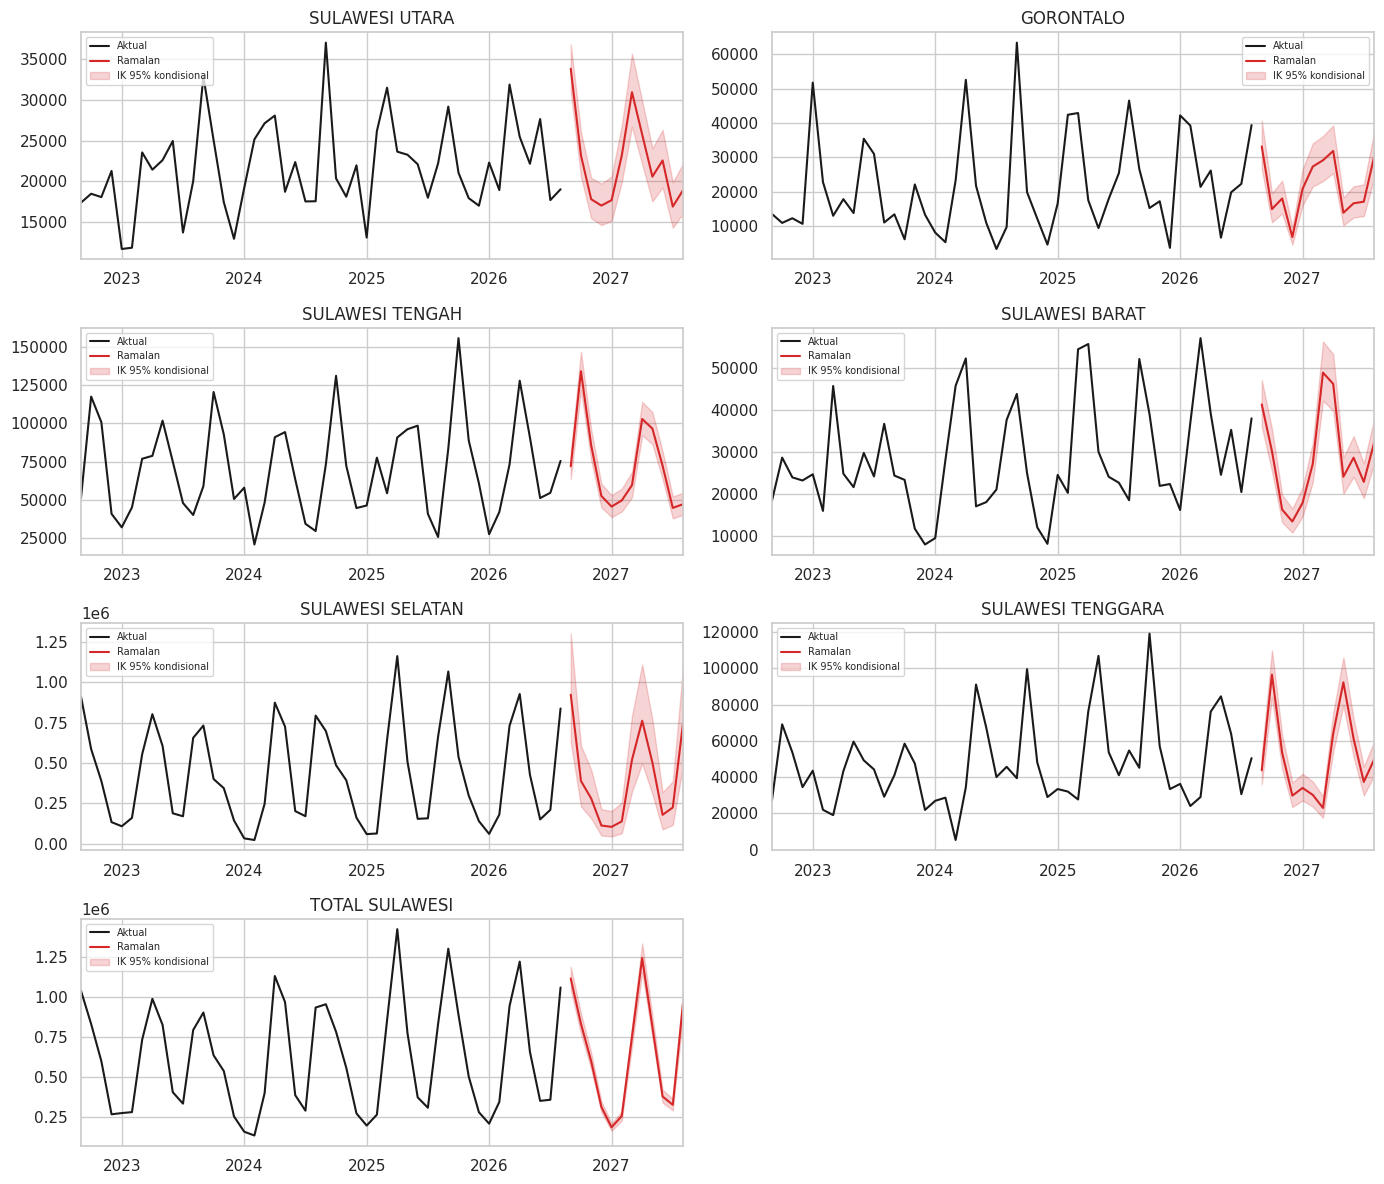

,Ramalan,Bawah 95%,Atas 95%,Metode
2026-09-01,1117664.0,1047075.0,1191472.0,SARIMAX
2026-10-01,833386.0,771263.0,898880.0,SARIMAX
2026-11-01,599254.0,549291.0,652270.0,SARIMAX
2026-12-01,311775.0,279794.0,346195.0,SARIMAX
2027-01-01,183475.0,161205.0,207783.0,SARIMAX
2027-02-01,254138.0,225847.0,284787.0,SARIMAX
2027-03-01,751139.0,690075.0,815836.0,SARIMAX
2027-04-01,1245932.0,1158182.0,1338169.0,SARIMAX
2027-05-01,815039.0,749268.0,884692.0,SARIMAX
2027-06-01,376783.0,338183.0,418323.0,SARIMAX


In [18]:
last=data[TARGET].index[-1]
fidx=pd.date_range(last+pd.offsets.MonthBegin(1),periods=H,freq="MS")
hasil_fc={};model_final={};full_conv=[]
for p in MODEL_PROV:
    var=model_pilih[p]
    y,ex=split(p,var=="SARIMAX")
    order,sorder,_=pilihan[(p,var)]
    r=fit(y,ex,order,sorder,maxiter=300)
    converged=bool(r.mle_retvals.get("converged",False))
    full_conv.append({"Provinsi":p,"Metode":var,"Konvergen full":converged})
    if not converged: warnings.warn(f"Final {p} {var} belum konvergen; ramalan perlu diverifikasi")
    ef=exog_skenario(p,last,fidx) if var=="SARIMAX" else None
    fc=r.get_forecast(H,exog=ef)
    ci=fc.conf_int(alpha=.05)
    hasil_fc[p]=pd.DataFrame({"Ramalan":kembali(fc.predicted_mean,p),
                              "Bawah 95%":kembali(ci.iloc[:,0],p),
                              "Atas 95%":kembali(ci.iloc[:,1],p),
                              "Metode":var},index=fidx)
    model_final[p]=r

print("Periode ramalan:",fidx[0].strftime("%Y-%m"),"s.d.",fidx[-1].strftime("%Y-%m"))
display(pd.DataFrame(full_conv).set_index("Provinsi"))
fig,axes=plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    data[TARGET][p].iloc[-48:].plot(ax=ax,color="k",label="Aktual")
    hasil_fc[p]["Ramalan"].plot(ax=ax,color="tab:red",label="Ramalan")
    ax.fill_between(fidx,hasil_fc[p]["Bawah 95%"],hasil_fc[p]["Atas 95%"],
                    color="tab:red",alpha=.2,label="IK 95% kondisional")
    ax.set_title(p);ax.legend(fontsize=7)
for ax in axes.ravel()[len(MODEL_PROV):]:ax.axis("off")
plt.tight_layout();plt.show()
display(hasil_fc[TOTAL].round(0))

In [19]:
rg=[]
for p in MODEL_PROV:
    a=data[TARGET][p].iloc[-12:].sum();b=hasil_fc[p]["Ramalan"].sum()
    rg.append({"Provinsi":p,"Metode":model_pilih[p],"Total 12 bln terakhir (aktual)":a,
               "Total 12 bln ke depan (ramalan)":b,"Perubahan (%)":(b/a-1)*100 if a>0 else np.nan})
ringkasan=pd.DataFrame(rg).set_index("Provinsi")
display(ringkasan.round(1))
# TOTAL dimodelkan tersendiri sehingga belum tentu sama dengan jumlah ramalan provinsi.
# Sediakan agregat bottom-up untuk kebutuhan identitas penjumlahan.
additive=pd.concat([hasil_fc[p]["Ramalan"].rename(p) for p in PULAU],axis=1).sum(axis=1)
perbandingan_total=pd.DataFrame({"Model total terpisah":hasil_fc[TOTAL]["Ramalan"],
                                  "Jumlah 6 model provinsi":additive})
display(perbandingan_total.round(0))

,Metode,Total 12 bln terakhir (aktual),Total 12 bln ke depan (ramalan),Perubahan (%)
Provinsi,,,,
SULAWESI UTARA,SARIMAX,270236.1,268311.2,-0.7
GORONTALO,SARIMAX,279720.4,259507.0,-7.2
SULAWESI TENGAH,SARIMAX,932526.5,863676.3,-7.4
SULAWESI BARAT,SARIMAX,403408.8,349561.2,-13.3
SULAWESI SELATAN,SARIMA,5579155.6,4891438.2,-12.3
SULAWESI TENGGARA,SARIMAX,649975.3,615530.9,-5.3
TOTAL SULAWESI,SARIMAX,8115022.7,7771323.9,-4.2


,Model total terpisah,Jumlah 6 model provinsi
2026-09-01,1117664.0,1148699.0
2026-10-01,833386.0,688756.0
2026-11-01,599254.0,473017.0
2026-12-01,311775.0,233334.0
2027-01-01,183475.0,241333.0
2027-02-01,254138.0,296714.0
2027-03-01,751139.0,712461.0
2027-04-01,1245932.0,1033619.0
2027-05-01,815039.0,751757.0
2027-06-01,376783.0,381283.0


## 8. Ekspor Hasil Excel

Hasil meliputi tabel Box–Cox (λ, interval kepercayaan, shift, keputusan), lag X dan hujan terpilih, CCF semua kandidat, stasioneritas ADF/KPSS, AIC/model terbaik, holdout, diagnostik, dan ramalan tiap provinsi. **Profil likelihood dan grafik perbandingan sebelum/sesudah Box–Cox ditampilkan di notebook ketika dijalankan.** Angka hasil notebook sebelumnya tidak dibawa karena spesifikasi dan transformasi berbeda.

In [20]:
filename=f"hasil_LAG_BOXCOX_sarima_sarimax_{PULAU_PILIH.lower()}.xlsx"
with pd.ExcelWriter(filename) as w:
    ringkas.to_excel(w,sheet_name="EDA")
    tabel_stl.to_excel(w,sheet_name="STL_Latih")
    kor.to_excel(w,sheet_name="Korelasi_Latih")
    tabel_boxcox.to_excel(w,sheet_name="BoxCox_Latih")
    tabel_lag.to_excel(w,sheet_name="Lag_CCF_Latih",index=False)
    tabel_lag_pilih.to_excel(w,sheet_name="Lag_Terpilih")
    tabel_stas.to_excel(w,sheet_name="Stasioner_Latih")
    tabel_orde.to_excel(w,sheet_name="Orde_dD")
    tabel_pilihan.to_excel(w,sheet_name="AIC_Latih")
    evaluasi.to_excel(w,sheet_name="Evaluasi_12_Bulan")
    pemenang.to_excel(w,sheet_name="Model_Terpilih")
    dg.to_excel(w,sheet_name="Diagnostik")
    ringkasan.to_excel(w,sheet_name="Ringkasan")
    perbandingan_total.to_excel(w,sheet_name="Total_Dua_Cara")
    for i,p in enumerate(MODEL_PROV):
        hasil_fc[p].to_excel(w,sheet_name=f"Ramalan_{i+1}_{p[:18]}")
try:
    from google.colab import files
    files.download(filename)
except ImportError:
    print("File disimpan di:",filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>